# EDA подписей и печатей — ДЗ №2

## Подготовка
Находим корень проекта, загружаем manifest и определяем общие функции. Пути относительные, случайная выборка воспроизводима.
Данные читаются без изменений. Метрики по маскам — технические признаки, не оценка модели или точности сегментации.

In [1]:
import csv
import hashlib
import html
import importlib.metadata
import json
import platform
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "context/HW2_PLAN.md").exists()
)
DATA = ROOT / "data/generated/crops_v1"
SIG = ROOT / "data/processed/signatures/subset_2500"
STAMP = ROOT / "data/processed/stamps/prepared_v1"
REPORT = ROOT / "reports/eda_crops"
REPORT.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261112)
cv2.setNumThreads(1)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 100})


def load_json(p):
    return json.loads(p.read_text(encoding="utf-8"))


def load_lines(p):
    return [
        json.loads(s) for s in p.read_text(encoding="utf-8").splitlines() if s.strip()
    ]


rows = load_lines(DATA / "manifest.jsonl")
rejected = load_lines(DATA / "quarantine_manifest.jsonl")
sources = load_lines(SIG / "manifest.jsonl")
source_qc = load_json(DATA / "source_signature_qc.json")
stamps = load_json(STAMP / "templates_main/manifest.json")
all_stamps = load_json(STAMP / "manifest.json")
source_by_id = {r["source_id"]: r for r in sources}
row_by_id = {r["sample_id"]: r for r in rows}
TASK = {"signature_comparison": "Подписи", "seal_comparison": "Печати"}
SPLITS = ("train", "val", "test")
notes, results = {}, {}


def native(v):
    if isinstance(v, np.generic):
        return v.item()
    if isinstance(v, dict):
        return {str(k): native(x) for k, x in v.items()}
    if isinstance(v, (tuple, list)):
        return [native(x) for x in v]
    return v


def save_json(name, v):
    (REPORT / name).write_text(
        json.dumps(native(v), ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


def table(items, name=None, limit=25):
    items = [native(r) for r in items]
    if not items:
        print("Записей нет.")
        return
    keys = list(dict.fromkeys(k for r in items for k in r))
    if name:
        with (REPORT / (name + ".csv")).open(
            "w", encoding="utf-8-sig", newline=""
        ) as f:
            w = csv.DictWriter(f, fieldnames=keys)
            w.writeheader()
            w.writerows(items)
    shown = items[:limit]
    plain = (
        "\t".join(keys)
        + "\n"
        + "\n".join("\t".join(str(r.get(k, "")) for k in keys) for r in shown)
    )
    markup = (
        "<table><thead><tr>"
        + "".join("<th>" + html.escape(k) + "</th>" for k in keys)
        + "</tr></thead><tbody>"
    )
    markup += (
        "".join(
            "<tr>"
            + "".join("<td>" + html.escape(str(r.get(k, ""))) + "</td>" for k in keys)
            + "</tr>"
            for r in shown
        )
        + "</tbody></table>"
    )
    display({"text/plain": plain, "text/html": markup}, raw=True)
    if len(items) > limit:
        print(
            f"Показано {limit} из {len(items)} строк; полный результат сохранён в CSV."
        )


def finish(fig, name):
    fig.tight_layout()
    fig.savefig(REPORT / (name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def read_image(path, mode=cv2.IMREAD_COLOR):
    a = cv2.imdecode(np.fromfile(str(path), np.uint8), mode)
    if a is None:
        raise ValueError(str(path))
    return a


def layer_alpha(r):
    return (
        read_image(SIG / "layers" / r["layer_file"], cv2.IMREAD_UNCHANGED)[
            ..., 3
        ].astype(np.float32)
        / 255
    )


def mask_stats(mask):
    b = (mask > 0.3).astype(np.uint8)
    yy, xx = np.nonzero(b)
    if not len(xx):
        return {
            "ink_pixels": 0,
            "components": 0,
            "largest_component": 0.0,
            "stroke_px": 0.0,
        }
    _, _, stats, _ = cv2.connectedComponentsWithStats(b)
    areas = stats[1:, cv2.CC_STAT_AREA]
    areas = areas[areas >= 3]
    d = cv2.distanceTransform(b, cv2.DIST_L2, 3)
    ridge = (d > 0) & (d >= cv2.dilate(d, np.ones((3, 3), np.uint8)))
    return {
        "ink_pixels": int(b.sum()),
        "components": len(areas),
        "largest_component": float(areas.max() / areas.sum()) if areas.size else 0.0,
        "stroke_px": float(2 * np.median(d[ridge])) if ridge.any() else 0.0,
        "bbox_w": int(xx.max() - xx.min() + 1),
        "bbox_h": int(yy.max() - yy.min() + 1),
        "cx": float(xx.mean() / b.shape[1]),
        "cy": float(yy.mean() / b.shape[0]),
        "edge": bool(b[0].any() or b[-1].any() or b[:, 0].any() or b[:, -1].any()),
    }


def letterbox(mask, side=128, crop_ink=True):
    yy, xx = np.nonzero(mask > 0.05)
    if not len(xx):
        return np.zeros((side, side), np.float32)
    a = (
        mask[yy.min() : yy.max() + 1, xx.min() : xx.max() + 1] if crop_ink else mask
    ).astype(np.float32)
    scale = (side - 8) / max(a.shape)
    a = cv2.resize(
        a,
        (max(1, round(a.shape[1] * scale)), max(1, round(a.shape[0] * scale))),
        interpolation=cv2.INTER_AREA,
    )
    out = np.zeros((side, side), np.float32)
    y = (side - a.shape[0]) // 2
    x = (side - a.shape[1]) // 2
    out[y : y + a.shape[0], x : x + a.shape[1]] = a
    return out


def scene_grid(chosen, name, cols=4, clean=False):
    if not chosen:
        print("Подходящих примеров нет.")
        return
    fig, axes = plt.subplots(
        (len(chosen) + cols - 1) // cols,
        cols,
        figsize=(cols * 3.5, ((len(chosen) + cols - 1) // cols) * 2.9),
        squeeze=False,
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, chosen):
        image = read_image(DATA / r["paths"]["clean_target" if clean else "images"])
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(r["sample_id"] + "\n" + r["condition"], fontsize=7)
    finish(fig, name)


def source_grid(chosen, name, cols=4):
    fig, axes = plt.subplots(
        (len(chosen) + cols - 1) // cols,
        cols,
        figsize=(cols * 3.3, ((len(chosen) + cols - 1) // cols) * 2.4),
        squeeze=False,
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, chosen):
        a = read_image(SIG / "images" / r["image_path"])
        ax.imshow(cv2.cvtColor(a, cv2.COLOR_BGR2RGB))
        ax.set_title(r["person_id"] + " / " + r["source_id"][:8], fontsize=8)
    finish(fig, name)


versions = {
    n: importlib.metadata.version(n)
    for n in (
        "numpy",
        "matplotlib",
        "opencv-python",
        "nbformat",
        "nbclient",
        "ipykernel",
    )
}
table([{"Python": platform.python_version(), **versions}], "environment")
print(
    f"Загружено {len(rows)} сцен, {len(sources)} исходных "
    f"подписей, {len(stamps)} основных шаблонов печатей."
)

Python,numpy,matplotlib,opencv-python,nbformat,nbclient,ipykernel
3.12.10,2.5.2,3.11.2,5.0.0.93,5.11.1,0.11.0,7.3.0


Загружено 4879 сцен, 2500 исходных подписей, 17 основных шаблонов печатей.


## 1. Состав и происхождение
**Что:** объёмы, источники, исключения и единицы наблюдения. **Как:** сверяем manifest исходников, генерации и карантина.
**Зачем:** отделить число изображений от числа независимых объектов и увидеть потери при подготовке.

Этап,Изображений,Identity
Подписи: подготовленные оригиналы,2500,250
Подписи: допущено к генерации,2392,249
Подписи: итоговые кропы,2383,248
Печати: основные шаблоны,17,16
Печати: итоговые кропы,2496,16
Готовые рендеры в карантине,13,—


Источник,Роль,Условия
Offline Handwriting Signature,Исходные образцы подписей; ID по каталогам источника,CC BY 4.0; DOI 10.17632/ghvhwcpkbg.1
Kaggle igorkarayman/signatures-and-stamps,Публичные страницы → кропы печатей → шаблоны,license Unknown; публикация файлов не согласована


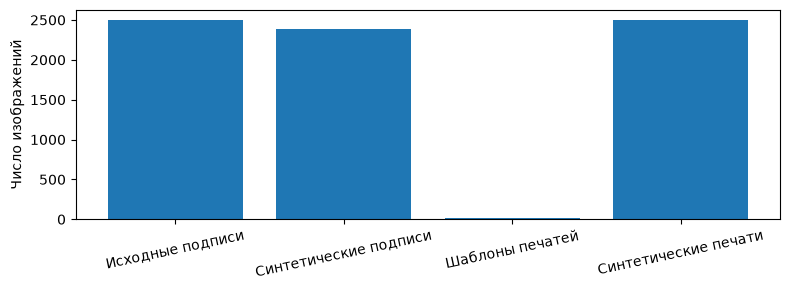

In [2]:
sig_rows = [r for r in rows if r["task"] == "signature_comparison"]
seal_rows = [r for r in rows if r["task"] == "seal_comparison"]
sig_rej = [r for r in rejected if r["task"] == "signature_comparison"]
seal_rej = [r for r in rejected if r["task"] == "seal_comparison"]
skipped = [q for q in source_qc if q["reasons"]]
counts = [
    {
        "Этап": "Подписи: подготовленные оригиналы",
        "Изображений": len(sources),
        "Identity": len({r["person_id"] for r in sources}),
    },
    {
        "Этап": "Подписи: допущено к генерации",
        "Изображений": len(sources) - len(skipped),
        "Identity": len({q["person_id"] for q in source_qc if not q["reasons"]}),
    },
    {
        "Этап": "Подписи: итоговые кропы",
        "Изображений": len(sig_rows),
        "Identity": len({r["person_id"] for r in sig_rows}),
    },
    {
        "Этап": "Печати: основные шаблоны",
        "Изображений": len(stamps),
        "Identity": len({r["seal_group_id"] for r in stamps}),
    },
    {
        "Этап": "Печати: итоговые кропы",
        "Изображений": len(seal_rows),
        "Identity": len({r["seal_group_id"] for r in seal_rows}),
    },
    {
        "Этап": "Готовые рендеры в карантине",
        "Изображений": len(rejected),
        "Identity": "—",
    },
]
table(counts, "01_composition")
assert len(sources) - len(skipped) - len(sig_rej) == len(sig_rows)
assert 2500 - len(seal_rej) == len(seal_rows)
assert len(rows) == len({r["sample_id"] for r in rows})
source_table = [
    {
        "Источник": "Offline Handwriting Signature",
        "Роль": "Исходные образцы подписей; ID по каталогам источника",
        "Условия": "CC BY 4.0; DOI 10.17632/ghvhwcpkbg.1",
    },
    {
        "Источник": "Kaggle igorkarayman/signatures-and-stamps",
        "Роль": "Публичные страницы → кропы печатей → шаблоны",
        "Условия": "license Unknown; публикация файлов не согласована",
    },
]
table(source_table, "01_sources")
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(
    [
        "Исходные подписи",
        "Синтетические подписи",
        "Шаблоны печатей",
        "Синтетические печати",
    ],
    [len(sources), len(sig_rows), len(stamps), len(seal_rows)],
)
ax.set_ylabel("Число изображений")
ax.tick_params(axis="x", labelrotation=12)
finish(fig, "01_counts")
results["composition"] = {
    "signatures": len(sig_rows),
    "people": len({r["person_id"] for r in sig_rows}),
    "stamps": len(seal_rows),
    "templates": len(stamps),
    "seal_groups": len({r["seal_group_id"] for r in seal_rows}),
    "source_skipped": len(skipped),
    "render_quarantine": len(rejected),
}
notes["01"] = (
    f"В наборе {len(sig_rows)} кропа подписей и {len(seal_rows)} "
    f"кропов печатей. У печатей только {len(stamps)} исходных "
    f"шаблонов: аугментации не увеличивают число независимых "
    f"оттисков. Разметки подделок в локальном manifest нет."
)

**Результат и вывод.** В наборе 2383 кропа подписей и 2496 кропов печатей. У печатей только 17 исходных шаблонов: аугментации не увеличивают число независимых оттисков. Разметки подделок в локальном manifest нет.

## 2. Дубликаты и рабочие identity
**Что:** точные повторы и визуально близкие исходники. **Как:** сравниваем хеши и pHash нормализованного слоя чернил; близкие пары показываем рядом.
**Зачем:** выявить возможные повторы и ошибки группировки. pHash ранжирует кандидатов и не подтверждает одинаковую личность или печать.

Проверка,Повторов
Точные копии оригинальных подписей,0
Точные хеши синтетических изображений,0


pHash distance / 63,left,right
2,open_writer_330/422810cf,open_writer_376/e95601e1
4,open_writer_004/b4166749,open_writer_405/83faf8a9
4,open_writer_008/deab875c,open_writer_088/dc082e52
4,open_writer_055/55a28c8c,open_writer_405/83faf8a9
4,open_writer_057/05e761ce,open_writer_365/bb62ebe1
4,open_writer_057/4400a83f,open_writer_405/83faf8a9
4,open_writer_057/0935e510,open_writer_417/fb667c48
4,open_writer_066/1c30ba03,open_writer_092/c9e69681
4,open_writer_066/4e5519c5,open_writer_179/527dde98
4,open_writer_083/620ca5f3,open_writer_144/88dbeda3


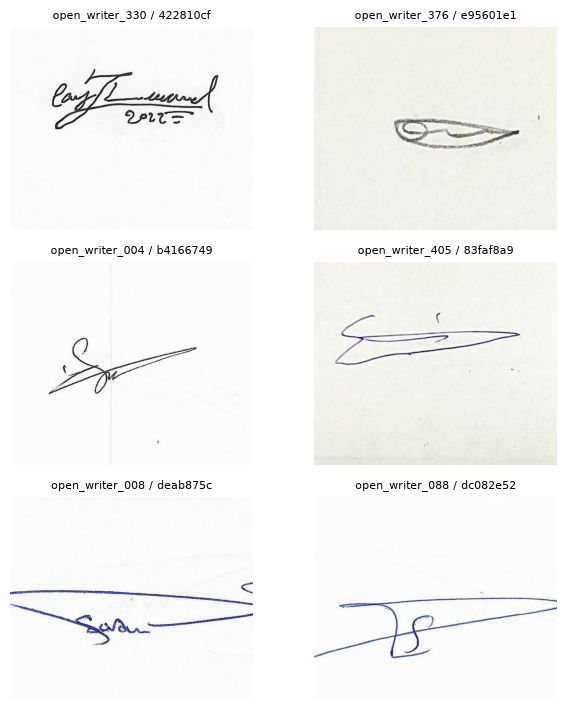

Слева,Справа,Решение,Обоснование
c0089,c0090,same_working_seal_group,Совпадают надписи кольца и реквизиты.
c0543,c0547,keep_separate,"Общий логотип USM, но разные номера 086/099."
c0819,c0963,keep_separate,"Различаются надписи, центральный рисунок или структура оттиска; одного сходства формы недостаточно."


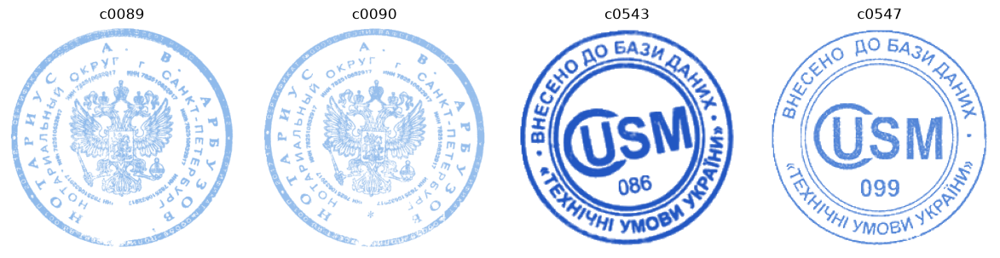

In [3]:
def phash(a):
    a = cv2.resize(letterbox(a, 128), (32, 32), interpolation=cv2.INTER_AREA)
    d = cv2.dct(a.astype(np.float32))[:8, :8].ravel()[1:]
    return d > np.median(d)


source_features = []
source_hashes = []
for r in sources:
    a = layer_alpha(r)
    source_features.append(
        {
            "source_id": r["source_id"],
            "person_id": r["person_id"],
            "split": r["split"],
            "native_w": a.shape[1],
            "native_h": a.shape[0],
            **mask_stats(a),
        }
    )
    source_hashes.append(phash(a))
sf_by_id = {r["source_id"]: r for r in source_features}
hashes = np.asarray(source_hashes)
people = np.asarray([r["person_id"] for r in sources])
nearest = []
for start in range(0, len(sources), 128):
    dist = np.count_nonzero(
        hashes[start : start + 128, None, :] != hashes[None, :, :], axis=2
    )
    same = people[start : start + 128, None] == people[None, :]
    dist[same] = 1000
    for i, ds in enumerate(dist):
        j = int(ds.argmin())
        left = start + i
        if left < j:
            nearest.append((int(ds[j]), left, j))
nearest = sorted(nearest)
near_rows = [
    {
        "pHash distance / 63": d,
        "left": sources[i]["person_id"] + "/" + sources[i]["source_id"][:8],
        "right": sources[j]["person_id"] + "/" + sources[j]["source_id"][:8],
    }
    for d, i, j in nearest[:12]
]
exact_source = len(sources) - len({r["pixel_sha256"] for r in sources})
exact_scene = len(rows) - len({r["image_sha256"] for r in rows})
table(
    [
        {"Проверка": "Точные копии оригинальных подписей", "Повторов": exact_source},
        {"Проверка": "Точные хеши синтетических изображений", "Повторов": exact_scene},
    ],
    "02_exact_duplicates",
)
table(near_rows, "02_near_signature_candidates")
source_grid(
    [sources[k] for _, i, j in nearest[:3] for k in (i, j)],
    "02_near_signature_examples",
    cols=2,
)
pair_review = load_json(STAMP / "identity_pair_review.json")
ids = {r["id"] for r in stamps}
table(
    [
        {
            "Слева": r["left"],
            "Справа": r["right"],
            "Решение": r["review_decision"],
            "Обоснование": r["reason"],
        }
        for r in pair_review
        if r["left"] in ids and r["right"] in ids
    ],
    "02_stamp_identity_review",
)
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, key in zip(axes, ["c0089", "c0090", "c0543", "c0547"]):
    ax.imshow(
        cv2.cvtColor(read_image(STAMP / "on_white" / f"{key}.png"), cv2.COLOR_BGR2RGB)
    )
    ax.set_title(key)
    ax.axis("off")
finish(fig, "02_stamp_identity_examples")
save_json(
    "02_near_signature_candidates.json",
    [
        {
            "distance": d,
            "left_source": sources[i]["source_id"],
            "right_source": sources[j]["source_id"],
        }
        for d, i, j in nearest[:30]
    ],
)
results["duplicates"] = {
    "exact_source_duplicates": exact_source,
    "exact_scene_hash_duplicates": exact_scene,
    "minimum_cross_person_phash_distance": nearest[0][0],
    "reviewed_stamp_pairs": len(
        [r for r in pair_review if r["left"] in ids and r["right"] in ids]
    ),
}
notes["02"] = (
    f"Точных повторов в подготовленных оригиналах: "
    f"{exact_source}; по хешам итоговых сцен: {exact_scene}. "
    f"Ближайшая пара разных ID имеет pHash-расстояние "
    f"{nearest[0][0]}/63 и требует визуальной интерпретации. "
    f"c0089/c0090 объединены в рабочую группу; c0543/c0547 "
    f"разделены по номерам 086/099. Остальные singleton-ID "
    f"независимо не подтверждены."
)

**Результат и вывод.** Точных повторов в подготовленных оригиналах: 0; по хешам итоговых сцен: 0. Ближайшая пара разных ID имеет pHash-расстояние 2/63 и требует визуальной интерпретации. c0089/c0090 объединены в рабочую группу; c0543/c0547 разделены по номерам 086/099. Остальные singleton-ID независимо не подтверждены. В показанных парах видны различия формы; объединять ID по одному pHash нельзя.

## 3. Образцы на identity и доступность пар
**Что:** число естественных образцов и синтетических вариантов на identity. **Как:** считаем распределения и число возможных пар разных исходников внутри группы.
**Зачем:** понять, где есть естественная внутригрупповая вариативность. Пары здесь только считаются; обучающие пары не создаются.

Подзадача,Групп,Min,Медиана,Max
Подписи,248,1,10.0,10
Печати,16,145,147.5,292


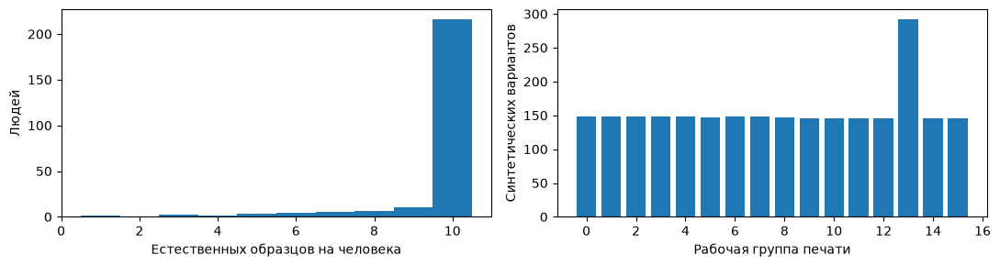

Человек,Образцов,Возможных положительных пар
open_writer_084,1,0
open_writer_006,3,3
open_writer_052,3,3
open_writer_330,4,6
open_writer_034,5,10
open_writer_082,5,10
open_writer_288,5,10
open_writer_158,6,15


Split,Людей,Положительные пары разных исходников,Отрицательные пары разных людей
train,198,8338,1797612
val,25,1057,27863
test,25,1060,27860


In [4]:
people_counts = Counter(r["person_id"] for r in sig_rows)
seal_counts = Counter(r["seal_group_id"] for r in seal_rows)
seal_source_groups = defaultdict(set)
for r in stamps:
    seal_source_groups[r["seal_group_id"]].add(r["id"])
table(
    [
        {
            "Подзадача": "Подписи",
            "Групп": len(people_counts),
            "Min": min(people_counts.values()),
            "Медиана": float(np.median(list(people_counts.values()))),
            "Max": max(people_counts.values()),
        },
        {
            "Подзадача": "Печати",
            "Групп": len(seal_counts),
            "Min": min(seal_counts.values()),
            "Медиана": float(np.median(list(seal_counts.values()))),
            "Max": max(seal_counts.values()),
        },
    ],
    "03_samples_per_identity",
)
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].hist(list(people_counts.values()), bins=np.arange(0.5, 11.5))
axes[0].set(xlabel="Естественных образцов на человека", ylabel="Людей")
axes[1].bar(range(len(seal_counts)), list(seal_counts.values()))
axes[1].set(xlabel="Рабочая группа печати", ylabel="Синтетических вариантов")
finish(fig, "03_identity_counts")
small = sorted(people_counts, key=people_counts.get)[:8]
table(
    [
        {
            "Человек": k,
            "Образцов": people_counts[k],
            "Возможных положительных пар": people_counts[k]
            * (people_counts[k] - 1)
            // 2,
        }
        for k in small
    ],
    "03_small_groups",
)
pair_stats = []
for split in SPLITS:
    count = Counter(r["person_id"] for r in sig_rows if r["split"] == split)
    ns = sum(count.values())
    positive = sum(n * (n - 1) // 2 for n in count.values())
    pair_stats.append(
        {
            "Split": split,
            "Людей": len(count),
            "Положительные пары разных исходников": positive,
            "Отрицательные пары разных людей": ns * (ns - 1) // 2 - positive,
        }
    )
table(pair_stats, "03_possible_signature_pairs")
results["identity_counts"] = {
    "minimum_signature_samples": min(people_counts.values()),
    "people_with_less_than_two": sum(n < 2 for n in people_counts.values()),
    "seal_groups_with_multiple_source_crops": sum(
        len(v) > 1 for v in seal_source_groups.values()
    ),
    "possible_signature_pairs": pair_stats,
}
notes["03"] = (
    f"У человека осталось от {min(people_counts.values())} до "
    f"{max(people_counts.values())} естественных образцов; групп "
    f"с менее чем двумя образцами: "
    f"{sum(n < 2 for n in people_counts.values())}. Несколько "
    f"исходных кропов имеют только "
    f"{sum(len(v) > 1 for v in seal_source_groups.values())} из "
    f"{len(seal_counts)} групп печатей; независимость этих "
    f"оттисков ещё требует подтверждения."
)

**Результат и вывод.** У человека осталось от 1 до 10 естественных образцов; групп с менее чем двумя образцами: 1. Несколько исходных кропов имеют только 1 из 16 групп печатей; независимость этих оттисков ещё требует подтверждения. Независимость разных исходных сканов не подтверждается одними хешами.

## Измерения для блоков 4–10
Однократно читаем все сцены: геометрия, штрихи, перекрытия, фон и параметры генерации.
Толщина — приближение по локальным максимумам distance transform; контраст — яркость фона минус яркость пикселей целевого объекта.
В наложениях этот контраст включает чужие чернила и не измеряет отдельно видимость подписи.

In [5]:
features = []
for index, r in enumerate(rows):
    content = (DATA / r["paths"]["images"]).read_bytes()
    assert hashlib.sha256(content).hexdigest() == r["image_sha256"]
    image = cv2.imdecode(np.frombuffer(content, np.uint8), cv2.IMREAD_COLOR)
    h, w = image.shape[:2]
    a = read_image(DATA / r["paths"]["alpha_signature"], cv2.IMREAD_GRAYSCALE) / 255
    b = read_image(DATA / r["paths"]["alpha_stamp"], cv2.IMREAD_GRAYSCALE) / 255
    target = a if r["task"] == "signature_comparison" else b
    ms, mt = a > 0.3, b > 0.3
    st = mask_stats(target)
    sigst = mask_stats(a)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255
    bg = ~(ms | mt)
    bg_value = (
        float(np.percentile(gray[bg], 90))
        if bg.any()
        else float(np.percentile(gray, 90))
    )
    contrast = bg_value - float(np.median(gray[target > 0.3]))
    bg_rgb = (image[bg].mean(axis=0)[::-1] / 255).tolist() if bg.any() else [0, 0, 0]
    meta = r.get("generator_metadata", r.get("degradation", {}))
    shared = int((ms & mt).sum())
    row = {
        "sample_id": r["sample_id"],
        "task": r["task"],
        "split": r["split"],
        "condition": r["condition"],
        "person_id": r.get("person_id"),
        "signature_source_id": r.get("signature_source_id"),
        "seal_group_id": r.get("seal_group_id"),
        "stamp_source_id": r.get("stamp_source_id"),
        "width": w,
        "height": h,
        "canvas_aspect": w / h,
        "bbox_aspect": st["bbox_w"] / st["bbox_h"],
        "ink_fraction": st["ink_pixels"] / (w * h),
        "bbox_fraction": st["bbox_w"] * st["bbox_h"] / (w * h),
        **st,
        "signature_stroke_px": sigst["stroke_px"],
        "signature_overlap_fraction": shared / max(1, int(ms.sum())),
        "stamp_overlap_fraction": shared / max(1, int(mt.sum())),
        "has_both": bool(ms.any() and mt.any()),
        "contrast_gray": contrast,
        "background_gray": bg_value,
        "bg_r": bg_rgb[0],
        "bg_g": bg_rgb[1],
        "bg_b": bg_rgb[2],
        "color_distance_rgb": meta.get("color_dist"),
        "signature_color_mode": r.get("signature_color_mode"),
        "jpeg": meta["jpeg"],
        "blur": meta["blur"],
        "scale": meta.get("sig_upscale")
        if r["task"] == "signature_comparison"
        else r["stamp_scale"],
        "rotation": r.get("stamp_rotation_degrees"),
        "source_layer_sha": r["signature_layer_sha256"]
        if r["task"] == "signature_comparison"
        else r["stamp_layer_sha256"],
    }
    for side in (64, 128, 224):
        normalized = letterbox(target, side, crop_ink=False)
        z = mask_stats(normalized)
        scale = (side - 8) / max(target.shape)
        area_scale = (max(1, round(w * scale)) / w) * (max(1, round(h * scale)) / h)
        row[f"stroke_at_{side}"] = z["stroke_px"]
        row[f"components_at_{side}"] = z["components"]
        row[f"largest_at_{side}"] = z["largest_component"]
        row[f"ink_area_ratio_at_{side}"] = z["ink_pixels"] / max(
            st["ink_pixels"] * area_scale, 1e-6
        )
    features.append(row)
    if (index + 1) % 1000 == 0:
        print(f"Измерено {index+1}/{len(rows)} сцен")
table(features, "scene_features", limit=3)
table(source_features, "source_signature_features", limit=3)
f_by_id = {r["sample_id"]: r for r in features}
save_json("scene_features.json", features)
save_json("source_signature_features.json", source_features)
print(f"Готово: {len(features)} сцен; хеши изображений совпадают с manifest.")

Измерено 1000/4879 сцен


Измерено 2000/4879 сцен


Измерено 3000/4879 сцен


Измерено 4000/4879 сцен


sample_id,task,split,condition,person_id,signature_source_id,seal_group_id,stamp_source_id,width,height,canvas_aspect,bbox_aspect,ink_fraction,bbox_fraction,ink_pixels,components,largest_component,stroke_px,bbox_w,bbox_h,cx,cy,edge,signature_stroke_px,signature_overlap_fraction,stamp_overlap_fraction,has_both,contrast_gray,background_gray,bg_r,bg_g,bg_b,color_distance_rgb,signature_color_mode,jpeg,blur,scale,rotation,source_layer_sha,stroke_at_64,components_at_64,largest_at_64,ink_area_ratio_at_64,stroke_at_128,components_at_128,largest_at_128,ink_area_ratio_at_128,stroke_at_224,components_at_224,largest_at_224,ink_area_ratio_at_224
sig_0000__sig_000,signature_comparison,train,plain,open_writer_001,1af97057a066bbb32bba,None,None,548,335,1.635820895522388,1.5833333333333333,0.0336474561499074,0.4483494934088681,6177,3,0.9894770924396956,3.819999933242798,361,228,0.4820052963134964,0.5254929819092976,False,3.819999933242798,0.0,0.0,False,0.6980392038822174,0.9529411792755127,0.941176293744839,0.9384212946859776,0.9550663035629634,None,None,93,0.32,0.98,None,c46283177f079c9767467d4f312e72de7674e31759fda3ba0904203a4abe5bb3,1.909999966621399,8,0.5368421052631579,1.5453114222862532,1.909999966621399,2,0.98989898989899,1.3468963151712459,1.909999966621399,3,0.9862424763542562,1.2122712246491318
sig_0000__sig_001,signature_comparison,train,form_line,open_writer_001,82a35b705692b8bb1604,None,None,589,264,2.231060606060606,2.289940828402367,0.031061892267325204,0.42060889026084275,4830,2,0.9993788819875776,3.819999933242798,387,169,0.465832885158197,0.5629007465963988,False,3.819999933242798,0.0,0.0,False,0.7411764711141586,0.9607843160629272,0.9282780793147705,0.947746385134968,0.9237143683353102,None,None,94,0.27,0.9,None,f2c183bbeb9a4964e8b7e677329076557c3c2096d28e9a04cc79674d030f9e43,1.909999966621399,4,0.7903225806451613,1.609689440993789,1.909999966621399,1,1.0,1.4457395905221992,1.909999966621399,1,1.0,1.258434184969371
sig_0000__sig_002,signature_comparison,train,stamp_different_color,open_writer_001,39bb9e09593223a94249,seal_c0572,c0572,328,181,1.8121546961325967,1.88135593220339,0.039701522705834796,0.4412478102681579,2357,3,0.9473907509546033,1.909999966621399,222,118,0.5316661837598435,0.5731745335980517,False,1.909999966621399,0.25965210012728046,0.04402560966836918,True,0.7647058814764023,0.9843137264251709,0.9249440538303058,0.9629892430875648,0.9583462715858038,0.611,None,95,0.27,0.45,None,0cec4b76f2cb51463fef5d5974bb3e504585f298d8e96313ee9ea697defe46de,1.909999966621399,10,0.40336134453781514,1.7411025888176992,1.909999966621399,2,0.9929742388758782,1.3579867405493202,1.909999966621399,2,0.9951534733441034,1.2131451552949468


Показано 3 из 4879 строк; полный результат сохранён в CSV.


source_id,person_id,split,native_w,native_h,ink_pixels,components,largest_component,stroke_px,bbox_w,bbox_h,cx,cy,edge
1af97057a066bbb32bba,open_writer_001,train,377,229,5018,2,0.9924272618573137,3.819999933242798,369,221,0.489869890146137,0.5688769338677704,False
82a35b705692b8bb1604,open_writer_001,train,437,198,4459,2,0.9908051132540928,3.819999933242798,429,190,0.46498763460422265,0.5871588728731586,False
39bb9e09593223a94249,open_writer_001,train,496,269,6982,2,0.996562589515898,3.819999933242798,488,261,0.5517777279825542,0.5980780104762219,False


Показано 3 из 2500 строк; полный результат сохранён в CSV.


Готово: 4879 сцен; хеши изображений совпадают с manifest.


## 4. Размеры и сохранность деталей
**Что:** размеры кропов, пропорции, заполнение кадра и штрихи после нормализации. **Как:** распределения и диагностический letterbox всего кадра в 64/128/224 px с полями по 4 px.
**Зачем:** выбрать предобработку и увидеть потерю деталей. Эти размеры — варианты для анализа, не утверждённый вход модели; новые данные не генерируются.
Отношение площади чернил учитывает масштабирование; оно чувствительно к порогу 0.3 и не является точностью распознавания.

Объект,Признак,Min,P10,Медиана,P90,Max
Подписи,"Ширина кропа, px",153.0,372.0,489.0,605.8,678.0
Подписи,"Высота кропа, px",73.0,181.0,308.0,461.0,659.0
Подписи,Пропорции объекта W/H,0.5,1.03,1.6,2.694,6.761
Подписи,Доля bbox в кадре,0.312,0.406,0.432,0.461,0.579
Печати,"Ширина кропа, px",166.0,188.0,266.0,349.0,361.0
Печати,"Высота кропа, px",166.0,188.0,266.0,349.0,361.0
Печати,Пропорции объекта W/H,0.918,0.975,1.0,1.013,1.084
Печати,Доля bbox в кадре,0.408,0.431,0.446,0.465,0.485


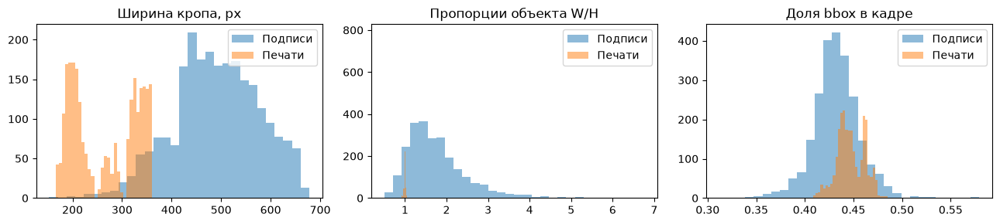

Объект,"Вход, px","Медиана толщины, px",Пустых масок,"Компонент стало >2×, %","Компонент осталось <50%, %","Площадь чернил / ожидаемую, медиана"
Подписи,64,1.91,0,8.85,8.64,1.658
Подписи,128,1.91,0,0.13,11.79,1.386
Подписи,224,1.91,0,0.0,4.36,1.224
Печати,64,1.91,0,0.0,97.16,1.097
Печати,128,1.91,0,0.0,50.04,1.081
Печати,224,1.91,0,0.0,0.08,1.045


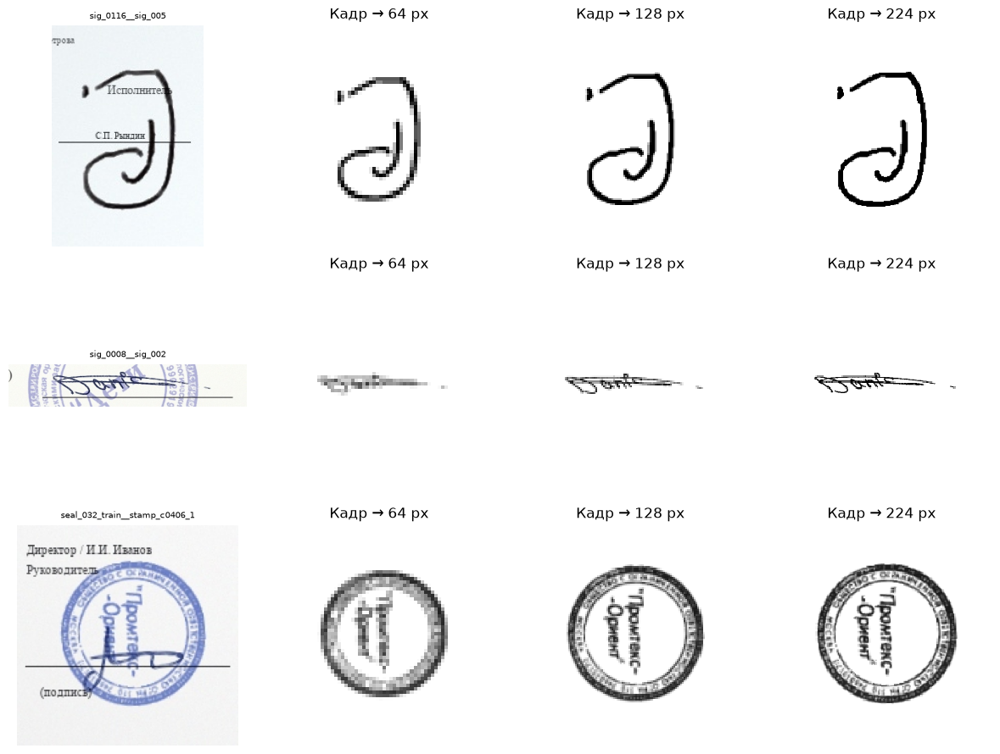

In [6]:
geometry = []
for task, label in TASK.items():
    fs = [f for f in features if f["task"] == task]
    for key, title in [
        ("width", "Ширина кропа, px"),
        ("height", "Высота кропа, px"),
        ("bbox_aspect", "Пропорции объекта W/H"),
        ("bbox_fraction", "Доля bbox в кадре"),
    ]:
        x = np.array([f[key] for f in fs])
        p = np.percentile(x, [0, 10, 50, 90, 100])
        geometry.append(
            {
                "Объект": label,
                "Признак": title,
                "Min": round(p[0], 3),
                "P10": round(p[1], 3),
                "Медиана": round(p[2], 3),
                "P90": round(p[3], 3),
                "Max": round(p[4], 3),
            }
        )
table(geometry, "04_geometry")
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for task, label in TASK.items():
    fs = [f for f in features if f["task"] == task]
    for ax, key in zip(axes, ["width", "bbox_aspect", "bbox_fraction"]):
        ax.hist([f[key] for f in fs], bins=30, alpha=0.5, label=label)
for ax, title in zip(
    axes, ["Ширина кропа, px", "Пропорции объекта W/H", "Доля bbox в кадре"]
):
    ax.set_title(title)
    ax.legend()
finish(fig, "04_geometry")
resize_stats = []
for task, label in TASK.items():
    fs = [f for f in features if f["task"] == task]
    for side in (64, 128, 224):
        resize_stats.append(
            {
                "Объект": label,
                "Вход, px": side,
                "Медиана толщины, px": round(
                    float(np.median([f[f"stroke_at_{side}"] for f in fs])), 2
                ),
                "Пустых масок": sum(f[f"stroke_at_{side}"] == 0 for f in fs),
                "Компонент стало >2×, %": round(
                    100
                    * np.mean(
                        [
                            f[f"components_at_{side}"] > max(8, 2 * f["components"])
                            for f in fs
                        ]
                    ),
                    2,
                ),
                "Компонент осталось <50%, %": round(
                    100
                    * np.mean(
                        [f[f"components_at_{side}"] < f["components"] / 2 for f in fs]
                    ),
                    2,
                ),
                "Площадь чернил / ожидаемую, медиана": round(
                    float(np.median([f[f"ink_area_ratio_at_{side}"] for f in fs])), 3
                ),
            }
        )
table(resize_stats, "04_resize_diagnostics")
extreme = [
    min(features, key=lambda f: f["width"]),
    max(features, key=lambda f: f["bbox_aspect"]),
    min(
        [f for f in features if f["task"] == "seal_comparison"],
        key=lambda f: f["width"],
    ),
]
chosen = [row_by_id[f["sample_id"]] for f in extreme]
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for i, r in enumerate(chosen):
    mask = (
        read_image(
            DATA
            / r["paths"][
                "alpha_signature"
                if r["task"] == "signature_comparison"
                else "alpha_stamp"
            ],
            cv2.IMREAD_GRAYSCALE,
        )
        / 255
    )
    axes[i, 0].imshow(
        cv2.cvtColor(read_image(DATA / r["paths"]["images"]), cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title(r["sample_id"], fontsize=7)
    for ax, side in zip(axes[i, 1:], (64, 128, 224)):
        ax.imshow(
            1 - letterbox(mask, side, crop_ink=False),
            cmap="gray",
            vmin=0,
            vmax=1,
            interpolation="nearest",
        )
        ax.set_title(f"Кадр → {side} px")
for ax in axes.flat:
    ax.axis("off")
finish(fig, "04_resize_examples")
edge_count = sum(f["edge"] for f in features)
results["geometry"] = {
    "stats": geometry,
    "resize": resize_stats,
    "target_boundary_count": edge_count,
}
notes["04"] = (
    f"Целевой объект касается края у {edge_count} сцен. "
    f"Нормализация заметно меняет детализацию; таблица показывает "
    f"толщину и фрагментацию при 64/128/224 px. Размер входа "
    f"следует выбрать после просмотра мелких печатей и вытянутых "
    f"подписей; пропорции сохранять, свободное место дополнять "
    f"полями."
)

**Результат и вывод.** Касаний края: 0. При 64 px число компонент подписи превышает max(8, 2×исходное) у 8.85% сцен. Менее половины компонент печати остаётся у 97.16% сцен при 64 px и 0.08% при 224 px. Исчезновение и слияние деталей требуют просмотра; пустых масок нет, но это не доказывает сохранность рисунка. Размер входа ещё не выбран.

## 5. Качество чернил и контраста
**Что:** слабые штрихи, фрагментация и возможное слипание. **Как:** распределения технических признаков и примеры нижнего контраста, тонких и толстых штрихов.
**Зачем:** проверить исправленную генерацию на полном наборе. Низкий контраст и раздельные росчерки — причины просмотра, не автоматическая оценка «плохо».

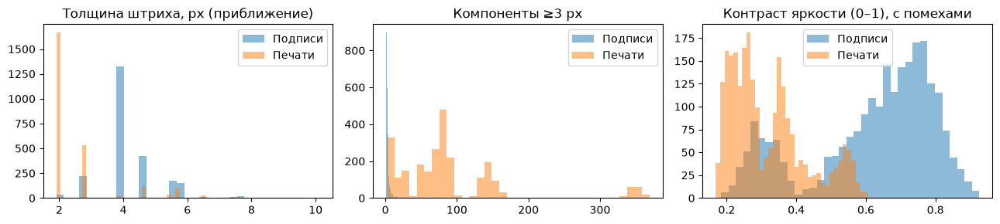

Объект,Признак,P10,Медиана,P90
Подписи,stroke_px,2.739,3.82,5.477
Подписи,components,1.0,2.0,6.0
Подписи,largest_component,0.743,0.992,1.0
Подписи,contrast_gray,0.31,0.669,0.808
Печати,stroke_px,1.91,1.91,4.649
Печати,components,7.0,77.0,151.0
Печати,largest_component,0.252,0.358,0.803
Печати,contrast_gray,0.2,0.282,0.51


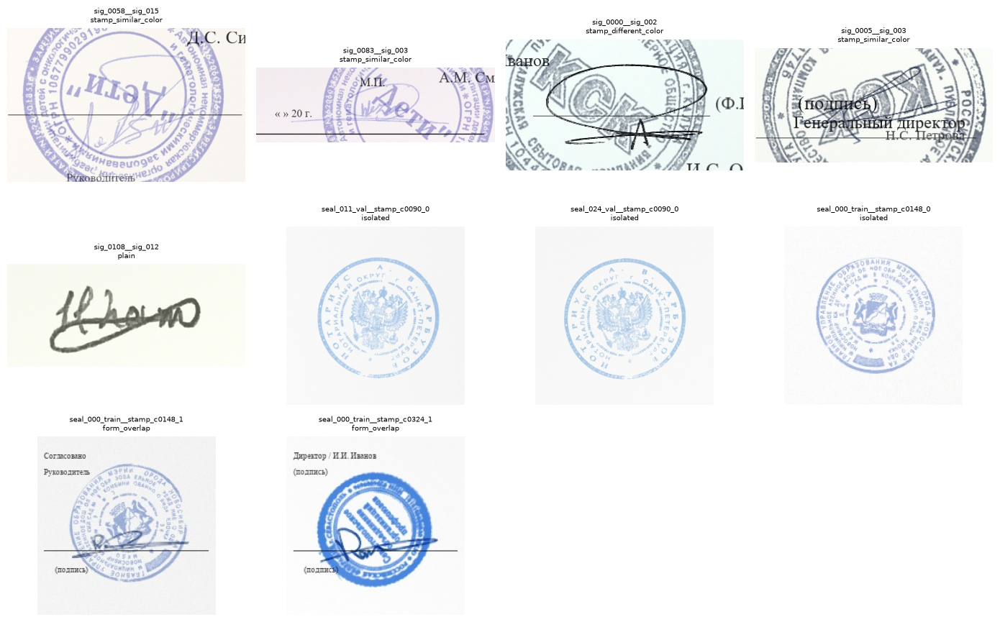

In [7]:
quality = []
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for task, label in TASK.items():
    fs = [f for f in features if f["task"] == task]
    for ax, key in zip(axes, ["stroke_px", "components", "contrast_gray"]):
        ax.hist([f[key] for f in fs], bins=35, alpha=0.5, label=label)
    for key in ("stroke_px", "components", "largest_component", "contrast_gray"):
        p = np.percentile([f[key] for f in fs], [10, 50, 90])
        quality.append(
            {
                "Объект": label,
                "Признак": key,
                "P10": round(p[0], 3),
                "Медиана": round(p[1], 3),
                "P90": round(p[2], 3),
            }
        )
for ax, title in zip(
    axes,
    [
        "Толщина штриха, px (приближение)",
        "Компоненты ≥3 px",
        "Контраст яркости (0–1), с помехами",
    ],
):
    ax.set_title(title)
    ax.legend()
finish(fig, "05_quality_distributions")
table(quality, "05_quality_summary")
quality_ids = []
for task in TASK:
    fs = [f for f in features if f["task"] == task]
    for key in ("contrast_gray", "stroke_px"):
        quality_ids.extend(f["sample_id"] for f in sorted(fs, key=lambda f: f[key])[:2])
    quality_ids.append(max(fs, key=lambda f: f["stroke_px"])["sample_id"])
quality_ids = list(dict.fromkeys(quality_ids))
scene_grid([row_by_id[k] for k in quality_ids], "05_quality_extremes")
save_json("05_quality_review_candidates.json", [f_by_id[k] for k in quality_ids])
thin = {
    TASK[t]: sum(f["stroke_px"] < 2 for f in features if f["task"] == t) for t in TASK
}
results["quality"] = {
    "summary": quality,
    "stroke_below_2px": thin,
    "review_candidates": quality_ids,
}
notes["05"] = (
    f"Оценка толщины <2 px: подписи {thin['Подписи']}, печати "
    f"{thin['Печати']}. У метода дискретный нижний уровень ≈1.91 "
    f"px; тонкий шрифт печатей естественен, этот порог не "
    f"означает брак и не требует общего утолщения. Крайние "
    f"примеры выведены для просмотра; контраст с помехами не "
    f"доказывает различимость подписи."
)

**Результат и вывод.** Оценка толщины <2 px: подписи 37, печати 1666. У метода дискретный нижний уровень ≈1.91 px; тонкий шрифт печатей естественен, этот порог не означает брак и не требует общего утолщения. Крайние примеры выведены для просмотра; контраст с помехами не доказывает различимость подписи.

## 6. Отсев и карантин
**Что:** причины исключений и смещение состава. **Как:** сравниваем прошедшие и отложенные исходники, считаем потери по людям и показываем примеры.
**Зачем:** понять, не удалил ли фильтр преимущественно тонкие или естественно раздельные подписи. Состав данных здесь не меняем.

Причина предварительного отсева,Срабатываний
many_disconnected_fragments_review_required,104
outside_current_geometry_envelope,4


Причина рендера,Сцен
rendered_signature_needs_review,13


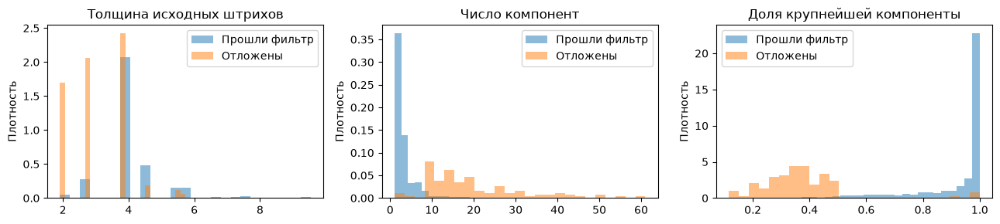

Человек,Было,Осталось,Потеряно
open_writer_277,10,0,10
open_writer_141,10,0,10
open_writer_084,10,1,9
open_writer_006,10,3,7
open_writer_052,10,3,7
open_writer_330,10,4,6
open_writer_082,10,5,5
open_writer_288,10,5,5
open_writer_034,10,5,5
open_writer_158,10,6,4


Показано 10 из 250 строк; полный результат сохранён в CSV.


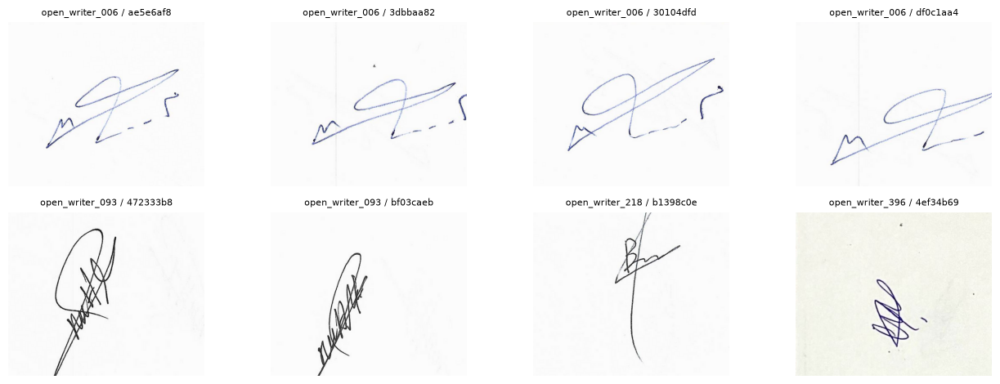

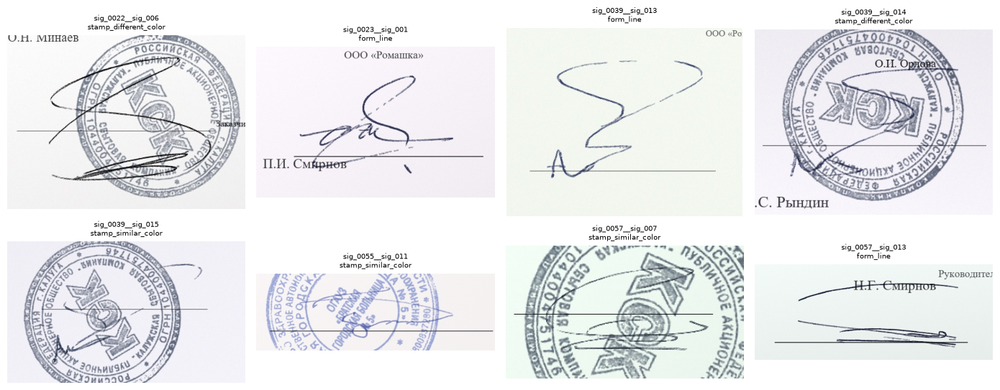

In [8]:
reason_counts = Counter(reason for q in source_qc for reason in q["reasons"])
table(
    [
        {"Причина предварительного отсева": k, "Срабатываний": v}
        for k, v in reason_counts.items()
    ],
    "06_source_reasons",
)
table(
    [
        {"Причина рендера": k, "Сцен": v}
        for k, v in Counter(r["rejection_reason"] for r in rejected).items()
    ],
    "06_render_reasons",
)
native_kept = [sf_by_id[q["source_id"]] for q in source_qc if not q["reasons"]]
native_skip = [sf_by_id[q["source_id"]] for q in source_qc if q["reasons"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for group, label in [(native_kept, "Прошли фильтр"), (native_skip, "Отложены")]:
    for ax, key in zip(axes, ["stroke_px", "components", "largest_component"]):
        ax.hist([f[key] for f in group], bins=25, alpha=0.5, density=True, label=label)
for ax, title in zip(
    axes, ["Толщина исходных штрихов", "Число компонент", "Доля крупнейшей компоненты"]
):
    ax.set_title(title)
    ax.set_ylabel("Плотность")
    ax.legend()
finish(fig, "06_selection_bias")
lost_people = sorted({r["person_id"] for r in sources} - set(people_counts))
loss_rows = [
    {
        "Человек": k,
        "Было": 10,
        "Осталось": people_counts.get(k, 0),
        "Потеряно": 10 - people_counts.get(k, 0),
    }
    for k in sorted(
        {r["person_id"] for r in sources}, key=lambda k: people_counts.get(k, 0)
    )
]
table(loss_rows, "06_losses_by_person", limit=10)
skipped_examples = []
for reason in reason_counts:
    skipped_examples.extend(
        [source_by_id[q["source_id"]] for q in source_qc if reason in q["reasons"]][:4]
    )
source_grid(skipped_examples[:8], "06_rejected_source_examples")
scene_grid(rejected[:8], "06_quarantine_examples")
results["selection"] = {
    "source_reason_counts": dict(reason_counts),
    "lost_people": lost_people,
    "retained_stroke_median": float(np.median([f["stroke_px"] for f in native_kept])),
    "skipped_stroke_median": float(np.median([f["stroke_px"] for f in native_skip])),
}
notes["06"] = (
    f"Полностью выпали {len(lost_people)} человека: "
    f"{', '.join(lost_people)}. Медиана толщины исходников: "
    f"прошли {results['selection']['retained_stroke_median']:.2f} "
    f"px, отложены "
    f"{results['selection']['skipped_stroke_median']:.2f} px. "
    f"Фильтр меняет распределение; отложенные образцы следует "
    f"пересматривать по причинам, не возвращать или удалять "
    f"автоматически."
)

**Результат и вывод.** Полностью выпали 2 человека: open_writer_141, open_writer_277. Медиана толщины исходников: прошли 3.82 px, отложены 2.74 px. Фильтр меняет распределение; отложенные образцы следует пересматривать по причинам, не возвращать или удалять автоматически.

## 7. Наложения и близость цветов
**Что:** сценарии, доля перекрытых чернил и близость цветов. **Как:** пересекаем сохранённые маски; RGB-расстояние берём только там, где оно записано генератором.
**Зачем:** отделить сложные наложения от потери информации. Пересечение масок не измеряет читаемость; чистые версии — диагностическая опора.

Задача,Сценарий,Сцен,"Доля внутри задачи, %"
Подписи,plain,600,25.2
Подписи,form_line,595,25.0
Подписи,stamp_different_color,595,25.0
Подписи,stamp_similar_color,593,24.9
Печати,isolated,1250,50.1
Печати,form_overlap,1246,49.9


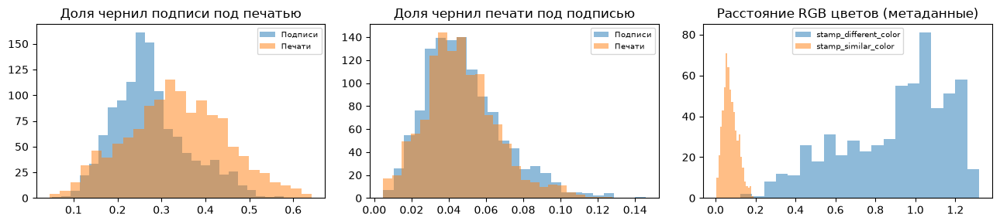

Задача,Сцен с обоими объектами,Подпись: медиана перекрытия,"Подпись: перекрыто >50%, сцен","Подпись: перекрыто >90%, сцен"
Подписи,1188,0.264,11,0
Печати,1246,0.332,91,0


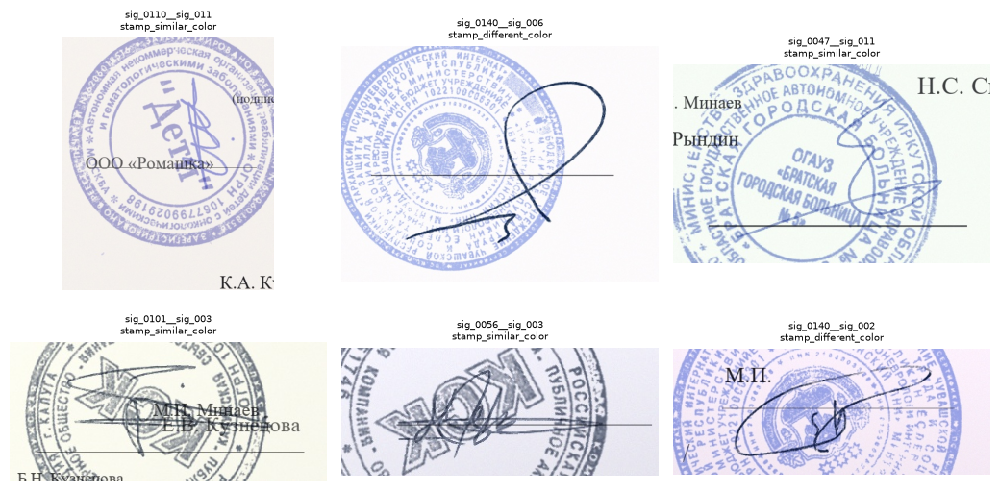

In [9]:
condition_counts = Counter((f["task"], f["condition"]) for f in features)
table(
    [
        {
            "Задача": TASK[t],
            "Сценарий": c,
            "Сцен": n,
            "Доля внутри задачи, %": round(
                100 * n / sum(f["task"] == t for f in features), 1
            ),
        }
        for (t, c), n in condition_counts.items()
    ],
    "07_conditions",
)
both = [f for f in features if f["has_both"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for task, label in TASK.items():
    fs = [f for f in both if f["task"] == task]
    axes[0].hist(
        [f["signature_overlap_fraction"] for f in fs], bins=25, alpha=0.5, label=label
    )
    axes[1].hist(
        [f["stamp_overlap_fraction"] for f in fs], bins=25, alpha=0.5, label=label
    )
axes[0].set_title("Доля чернил подписи под печатью")
axes[1].set_title("Доля чернил печати под подписью")
for cond in ("stamp_different_color", "stamp_similar_color"):
    fs = [
        f
        for f in features
        if f["condition"] == cond and f["color_distance_rgb"] is not None
    ]
    axes[2].hist([f["color_distance_rgb"] for f in fs], bins=20, alpha=0.5, label=cond)
axes[2].set_title("Расстояние RGB цветов (метаданные)")
for ax in axes:
    ax.legend(fontsize=7)
finish(fig, "07_overlap")
overlap_summary = []
for task, label in TASK.items():
    fs = [f for f in both if f["task"] == task]
    overlap_summary.append(
        {
            "Задача": label,
            "Сцен с обоими объектами": len(fs),
            "Подпись: медиана перекрытия": round(
                float(np.median([f["signature_overlap_fraction"] for f in fs])), 3
            ),
            "Подпись: перекрыто >50%, сцен": sum(
                f["signature_overlap_fraction"] > 0.5 for f in fs
            ),
            "Подпись: перекрыто >90%, сцен": sum(
                f["signature_overlap_fraction"] > 0.9 for f in fs
            ),
        }
    )
table(overlap_summary, "07_overlap_summary")
ordered = sorted(
    [f for f in both if f["task"] == "signature_comparison"],
    key=lambda f: f["signature_overlap_fraction"],
)
selected = [
    row_by_id[ordered[int(q * (len(ordered) - 1))]["sample_id"]]
    for q in (0, 0.25, 0.5, 0.75, 0.9, 1)
]
scene_grid(selected, "07_overlap_examples", cols=3)
results["overlap"] = {
    "summary": overlap_summary,
    "condition_counts": [
        {"task": t, "condition": c, "count": n}
        for (t, c), n in condition_counts.items()
    ],
}
notes["07"] = (
    f"Оба объекта присутствуют в {len(both)} сценах. При доле "
    f"перекрытия >90% кандидатов для просмотра: "
    f"{sum(f['signature_overlap_fraction'] > 0.9 for f in both)}. "
    f"Даже почти полное пересечение чернил не означает "
    f"невидимость при разных цветах; примеры надо оценивать "
    f"вместе с цветом и исходником. Доли сценариев заданы "
    f"генератором и не подтверждены на банковских данных."
)

**Результат и вывод.** Оба объекта присутствуют в 2434 сценах. При доле перекрытия >90% кандидатов для просмотра: 0. Даже почти полное пересечение чернил не означает невидимость при разных цветах; примеры надо оценивать вместе с цветом и исходником. Доли сценариев заданы генератором и не подтверждены на банковских данных.

## 8. Вариативность внутри и между identity
**Что:** разные естественные подписи одного человека и преобразования одной печати. **Как:** сравниваем pHash-расстояния внутри/между людьми и показываем группы исходников и сцен.
**Зачем:** обосновать будущие пары и ограничения синтетики. pHash здесь диагностический признак формы, не ML-бейзлайн и не биометрическая метрика.

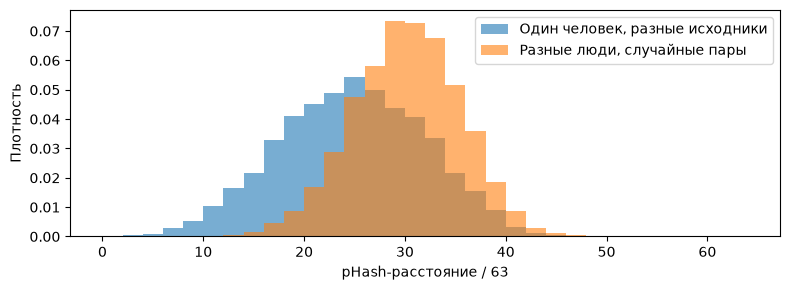

C:\Users\Kate\source\stamp_signature\.venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\Kate\source\stamp_signature\.venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


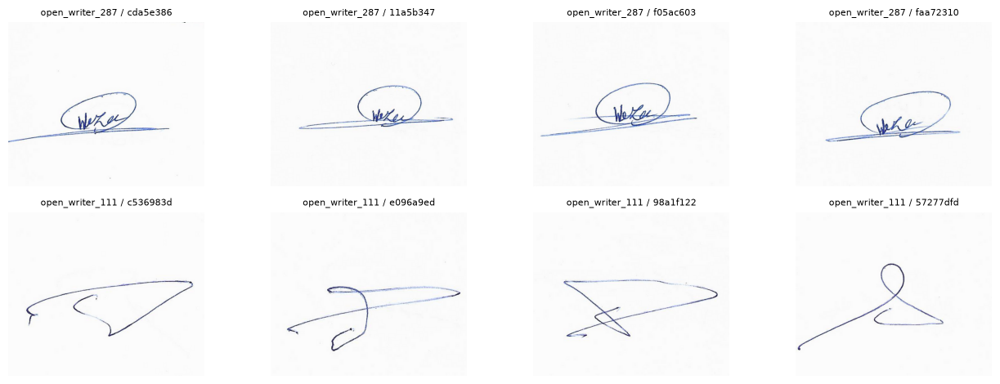

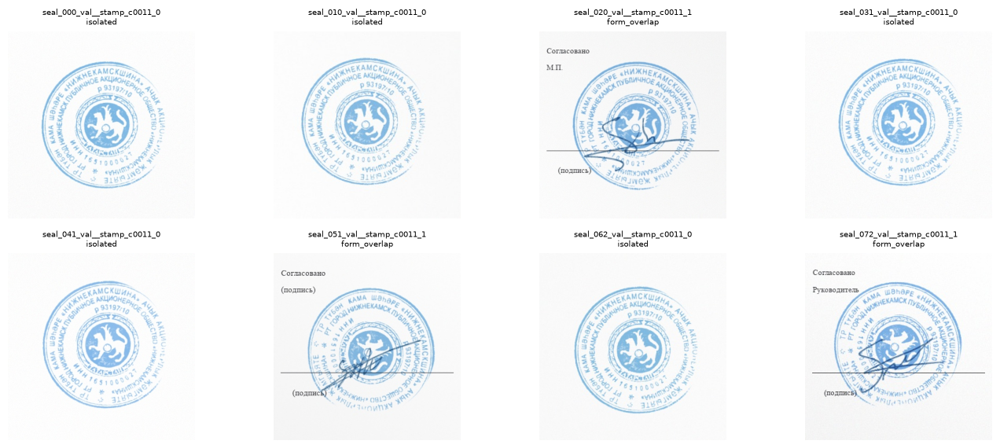

In [10]:
indices = defaultdict(list)
retained_source_ids = {x["signature_source_id"] for x in sig_rows}
for i, r in enumerate(sources):
    if r["source_id"] in retained_source_ids:
        indices[r["person_id"]].append(i)
within = []
for group in indices.values():
    for i, j in combinations(group, 2):
        within.append(int(np.count_nonzero(hashes[i] != hashes[j])))
between = []
eligible = np.array([i for group in indices.values() for i in group])
for _ in range(len(within)):
    i, j = RNG.choice(eligible, 2, replace=False)
    while people[i] == people[j]:
        j = int(RNG.choice(eligible))
    between.append(int(np.count_nonzero(hashes[i] != hashes[j])))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(
    within,
    bins=np.arange(0, 65, 2),
    alpha=0.6,
    density=True,
    label="Один человек, разные исходники",
)
ax.hist(
    between,
    bins=np.arange(0, 65, 2),
    alpha=0.6,
    density=True,
    label="Разные люди, случайные пары",
)
ax.set(xlabel="pHash-расстояние / 63", ylabel="Плотность")
ax.legend()
finish(fig, "08_within_between")
people_median = []
for key, group in indices.items():
    ds = [
        int(np.count_nonzero(hashes[i] != hashes[j])) for i, j in combinations(group, 2)
    ]
    people_median.append((float(np.median(ds)), key))
keys = [min(people_median)[1], max(people_median)[1]]
source_grid(
    [sources[i] for key in keys for i in indices[key][:4]],
    "08_natural_variation",
    cols=4,
)
seal_key = stamps[0]["id"]
variants = [r for r in seal_rows if r["stamp_source_id"] == seal_key]
scene_grid(
    [variants[i] for i in np.linspace(0, len(variants) - 1, 8, dtype=int)],
    "08_seal_variation",
)
results["variation"] = {
    "within_pairs": len(within),
    "random_between_pairs": len(between),
    "within_phash_median": float(np.median(within)),
    "between_phash_median": float(np.median(between)),
}
notes["08"] = (
    f"Медиана pHash-расстояния: внутри человека "
    f"{np.median(within):.1f}, между людьми "
    f"{np.median(between):.1f}. Распределения перекрываются, "
    f"поэтому простое сходство формы не задаёт надёжный порог. "
    f"Для подписей положительные пары следует брать из разных "
    f"естественных образцов; для печатей проверка на вариантах "
    f"одного шаблона останется ограниченной."
)

**Результат и вывод.** Медиана pHash-расстояния: внутри человека 24.0, между людьми 30.0. Распределения перекрываются, поэтому простое сходство формы не задаёт надёжный порог. Для подписей положительные пары следует брать из разных естественных образцов; для печатей проверка на вариантах одного шаблона останется ограниченной.

## 9. Разбиение и утечки
**Что:** пересечения исходников, людей, печатей и страниц между train/val/test; различия сложности.
**Как:** проверяем все роли объектов, строим распределения признаков по split и считаем число независимых групп.
**Зачем:** оценить пригодность рабочего разбиения. Протокол оценки пока не утверждён, test не используется для подбора порога или обучения.

Сущность,Уникальных,В нескольких split
person_id,248,0
signature_source_id,2385,0
signature_layer_sha256,2385,0
seal_group_id,16,0
stamp_layer_sha256,17,0
stamp_split_guard_group_id,16,0
source_page,16,0


Задача,Split,Сцен,Identity,Исходных образцов
Подписи,train,1901,198,1901
Подписи,val,241,25,241
Подписи,test,241,25,241
Печати,train,1766,12,12
Печати,val,438,2,3
Печати,test,292,2,2


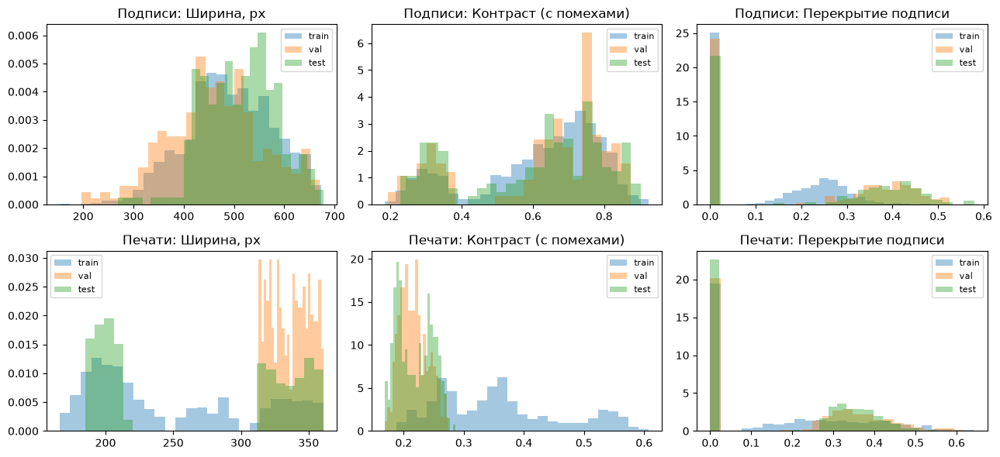

Задача,Split,Сценарий,"Доля, %"
Подписи,train,plain,25.14
Подписи,train,form_line,24.93
Подписи,train,stamp_different_color,24.99
Подписи,train,stamp_similar_color,24.93
Подписи,val,plain,25.31
Подписи,val,form_line,25.31
Подписи,val,stamp_different_color,24.9
Подписи,val,stamp_similar_color,24.48
Подписи,test,plain,25.31
Подписи,test,form_line,24.9


In [11]:
maps = {
    name: defaultdict(set)
    for name in (
        "person_id",
        "signature_source_id",
        "signature_layer_sha256",
        "seal_group_id",
        "stamp_layer_sha256",
        "stamp_split_guard_group_id",
        "source_page",
    )
}
stamp_by_id = {r["id"]: r for r in stamps}
for r in rows:
    for key in maps:
        value = (
            stamp_by_id[r["stamp_source_id"]]["source_page"]
            if key == "source_page" and r.get("stamp_source_id")
            else r.get(key)
        )
        if value:
            maps[key][value].add(r["split"])
leaks = {
    key: [k for k, v in groups.items() if len(v) > 1] for key, groups in maps.items()
}
table(
    [
        {
            "Сущность": key,
            "Уникальных": len(maps[key]),
            "В нескольких split": len(value),
        }
        for key, value in leaks.items()
    ],
    "09_leakage",
)
split_stats = []
for task, label in TASK.items():
    for split in SPLITS:
        subset = [r for r in rows if r["task"] == task and r["split"] == split]
        identity = "person_id" if task == "signature_comparison" else "seal_group_id"
        split_stats.append(
            {
                "Задача": label,
                "Split": split,
                "Сцен": len(subset),
                "Identity": len({r[identity] for r in subset}),
                "Исходных образцов": len(
                    {
                        r["signature_source_id"]
                        if task == "signature_comparison"
                        else r["stamp_source_id"]
                        for r in subset
                    }
                ),
            }
        )
table(split_stats, "09_split_counts")
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for row, (task, label) in enumerate(TASK.items()):
    for ax, key, title in zip(
        axes[row],
        ["width", "contrast_gray", "signature_overlap_fraction"],
        ["Ширина, px", "Контраст (с помехами)", "Перекрытие подписи"],
    ):
        for split in SPLITS:
            fs = [f[key] for f in features if f["task"] == task and f["split"] == split]
            ax.hist(fs, bins=25, alpha=0.4, density=True, label=split)
        ax.set_title(label + ": " + title)
        ax.legend(fontsize=8)
finish(fig, "09_split_distributions")
condition_split = []
for task in TASK:
    for split in SPLITS:
        fs = [f for f in features if f["task"] == task and f["split"] == split]
        for cond, n in Counter(f["condition"] for f in fs).items():
            condition_split.append(
                {
                    "Задача": TASK[task],
                    "Split": split,
                    "Сценарий": cond,
                    "Доля, %": round(100 * n / len(fs), 2),
                }
            )
table(condition_split, "09_condition_split", limit=30)
results["split"] = {
    "leak_counts": {k: len(v) for k, v in leaks.items()},
    "groups": split_stats,
    "condition_shares": condition_split,
}
seal_parts = {
    s: len({r["seal_group_id"] for r in seal_rows if r["split"] == s}) for s in SPLITS
}
notes["09"] = (
    f"Пересечений проверяемых групп между split: "
    f"{sum(map(len, leaks.values()))}, включая объекты-помехи. "
    f"Групп печатей train/val/test: "
    f"{seal_parts['train']}/{seal_parts['val']}/{seal_parts['test']}. "
    f"При таком числе групп val/test оценка печатей будет "
    f"нестабильной; разумно рассмотреть групповую кросс-валидацию "
    f"и дополнение независимыми оттисками. Это предложение, не "
    f"принятое изменение split."
)

**Результат и вывод.** Пересечений проверяемых групп: 0, включая помехи. Групп печатей train/val/test: 12/2/2; на графиках различаются размеры и контраст между частями. Нужно обсудить групповую кросс-валидацию и добавить независимые оттиски. Текущее разбиение не менялось.

## 10. Артефакты генерации и сопоставление с реальными кропами
**Что:** связь identity со сценарием/цветом/геометрией и отличие исходных кропов от синтетики. **Как:** таблицы связей и примеры «реальный кроп → очищенный слой → сцена».
**Зачем:** обнаружить подсказки генератора и ограничения переноса. Проверку на реальных документах банка этот анализ не заменяет.

Проверка,Таких групп,Всего групп
Людей с единственным сценарием,1,248
Групп печатей с одним режимом цвета подписи-помехи,15,16


Шаблон,Identity,Split,Режимы цвета подписи,"Родной размер, max px"
c0011,seal_c0011,val,similar_to_stamp,300
c0030,seal_c0030,test,similar_to_stamp,529
c0089,seal_c0089,val,dark_signature,365
c0090,seal_c0089,val,similar_to_stamp,362
c0148,seal_c0148,train,similar_to_stamp,167
c0203,seal_c0203,test,dark_signature,154
c0257,seal_c0257,train,dark_signature,146
c0324,seal_c0324,train,similar_to_stamp,150
c0359,seal_c0359,train,dark_signature,174
c0406,seal_c0406,train,similar_to_stamp,138


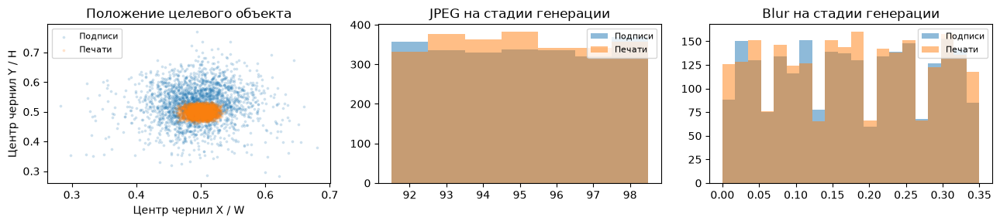

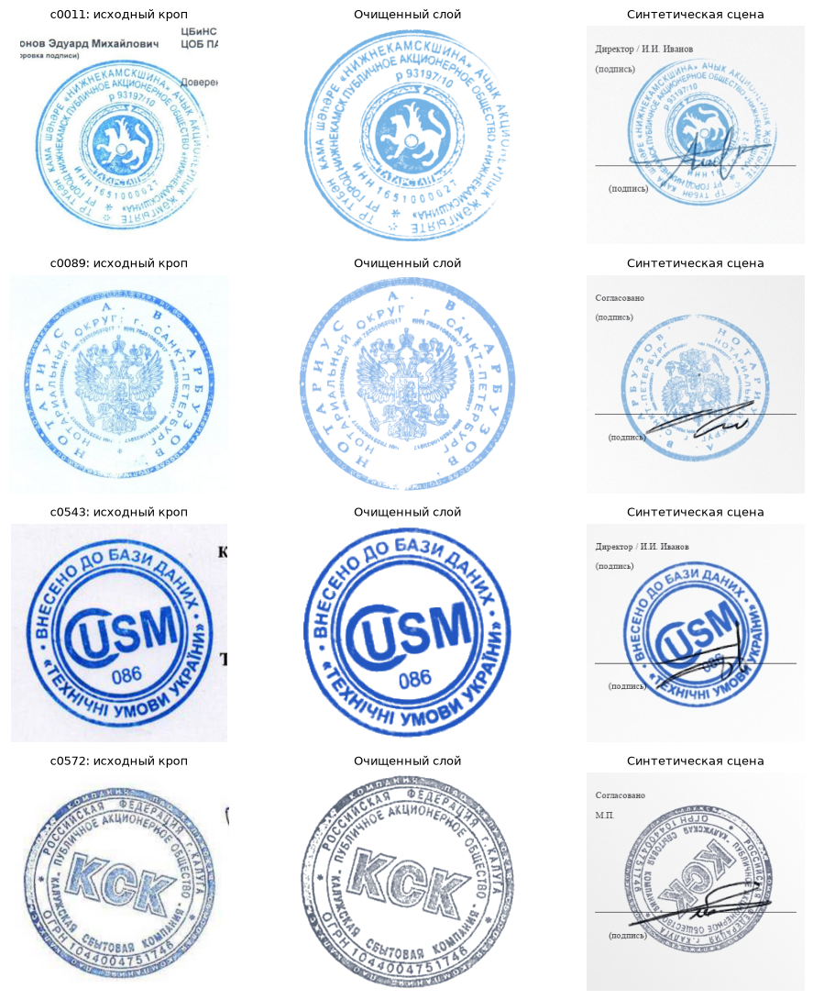

Ограничение,Количество
Шаблонов с одним режимом цвета подписи-помехи,17
Шаблонов печатей меньше 250 px,10
Сохранённых сложных реальных кропов (вне синтетического набора),12


In [12]:
person_conditions = defaultdict(set)
seal_modes = defaultdict(set)
for r in rows:
    if r["task"] == "signature_comparison":
        person_conditions[r["person_id"]].add(r["condition"])
    if r["task"] == "seal_comparison" and r["condition"] == "form_overlap":
        seal_modes[r["seal_group_id"]].add(r["signature_color_mode"])
mixing = [
    {
        "Проверка": "Людей с единственным сценарием",
        "Таких групп": sum(len(v) == 1 for v in person_conditions.values()),
        "Всего групп": len(person_conditions),
    },
    {
        "Проверка": "Групп печатей с одним режимом цвета подписи-помехи",
        "Таких групп": sum(len(v) == 1 for v in seal_modes.values()),
        "Всего групп": len(seal_modes),
    },
]
table(mixing, "10_identity_scene_association")
stamp_condition_rows = []
for r in stamps:
    group = [
        x
        for x in seal_rows
        if x["stamp_source_id"] == r["id"] and x["condition"] == "form_overlap"
    ]
    stamp_condition_rows.append(
        {
            "Шаблон": r["id"],
            "Identity": r["seal_group_id"],
            "Split": group[0]["split"],
            "Режимы цвета подписи": ", ".join(
                sorted({x["signature_color_mode"] for x in group})
            ),
            "Родной размер, max px": max(r["layer_width"], r["layer_height"]),
        }
    )
table(stamp_condition_rows, "10_stamp_color_identity", limit=20)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for task, label in TASK.items():
    fs = [f for f in features if f["task"] == task]
    axes[0].scatter(
        [f["cx"] for f in fs], [f["cy"] for f in fs], s=3, alpha=0.15, label=label
    )
    axes[1].hist(
        [f["jpeg"] for f in fs], bins=np.arange(91.5, 99.5), alpha=0.5, label=label
    )
    axes[2].hist([f["blur"] for f in fs], bins=20, alpha=0.5, label=label)
axes[0].set(
    xlabel="Центр чернил X / W",
    ylabel="Центр чернил Y / H",
    title="Положение целевого объекта",
)
axes[1].set_title("JPEG на стадии генерации")
axes[2].set_title("Blur на стадии генерации")
for ax in axes:
    ax.legend(fontsize=8)
finish(fig, "10_generator_artifacts")
chosen_ids = ["c0011", "c0089", "c0543", "c0572"]
fig, axes = plt.subplots(len(chosen_ids), 3, figsize=(10, 11))
for i, key in enumerate(chosen_ids):
    original = read_image(
        ROOT / "data/processed/stamps/selected_current/crops" / f"{key}.png"
    )
    clean = read_image(STAMP / "on_white" / f"{key}.png")
    generated = next(
        r
        for r in seal_rows
        if r["stamp_source_id"] == key and r["condition"] == "form_overlap"
    )
    scene = read_image(DATA / generated["paths"]["images"])
    for ax, img, title in zip(
        axes[i],
        [original, clean, scene],
        [key + ": исходный кроп", "Очищенный слой", "Синтетическая сцена"],
    ):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
finish(fig, "10_real_source_synthetic")
fixed_color_templates = sum(
    len(
        {
            r["signature_color_mode"]
            for r in seal_rows
            if r["stamp_source_id"] == s["id"] and r["condition"] == "form_overlap"
        }
    )
    == 1
    for s in stamps
)
real_only = [r for r in all_stamps if r["quality_group"] == "real_only"]
table(
    [
        {
            "Ограничение": "Шаблонов с одним режимом цвета подписи-помехи",
            "Количество": fixed_color_templates,
        },
        {
            "Ограничение": "Шаблонов печатей меньше 250 px",
            "Количество": sum(
                max(r["layer_width"], r["layer_height"]) < 250 for r in stamps
            ),
        },
        {
            "Ограничение": (
                "Сохранённых сложных реальных кропов (вне синтетического набора)"
            ),
            "Количество": len(real_only),
        },
    ],
    "10_domain_limits",
)
results["artifacts"] = {
    "fixed_color_templates": fixed_color_templates,
    "seal_templates": len(stamps),
    "association": mixing,
    "small_seal_templates": sum(
        max(r["layer_width"], r["layer_height"]) < 250 for r in stamps
    ),
    "real_only_crops": len(real_only),
}
notes["10"] = (
    f"У {fixed_color_templates} из {len(stamps)} шаблонов печатей "
    f"режим цвета подписи-помехи закреплён за шаблоном. Это "
    f"потенциальная подсказка генератора: перед обучением режимы "
    f"следует перемешать независимо от identity, затем повторить "
    f"контроль. Сопоставление с исходными кропами показывает "
    f"преобразование этих же источников, а не независимую "
    f"проверку синтетики на реальных данных."
)

**Результат и вывод.** У 17 из 17 шаблонов печатей режим цвета подписи-помехи закреплён за шаблоном. Это потенциальная подсказка генератора: перед обучением режимы следует перемешать независимо от identity, затем повторить контроль. Сопоставление с исходными кропами показывает преобразование этих же источников, а не независимую проверку синтетики на реальных данных.

## Итог и необходимые решения
Сводим измеренные ограничения и действия для следующего обсуждения. Набор и разбиение в ходе EDA не меняются.

In [13]:
decisions = [
    {
        "Наблюдение": (
            f"{len(sig_rows)} подписей / {len(people_counts)} людей; "
            f"{len(seal_rows)} печатей / {len(seal_counts)} групп"
        ),
        "Решение": "Оценивать объём по независимым identity и исходным образцам.",
    },
    {
        "Наблюдение": (
            f"Печати val/test: {seal_parts['val']}/{seal_parts['test']} групп"
        ),
        "Решение": (
            "Согласовать групповую валидацию; добавить независимые реальные оттиски."
        ),
    },
    {
        "Наблюдение": (
            f"У {fixed_color_templates}/{len(stamps)} шаблонов закреплён "
            f"цветовой режим помехи"
        ),
        "Решение": "Отвязать цвет и прочие параметры от identity перед обучением.",
    },
    {
        "Наблюдение": "Детализация меняется при нормализации",
        "Решение": (
            "Согласовать вход модели; сохранять пропорции и проверить тонкие штрихи."
        ),
    },
    {
        "Наблюдение": (
            f"Предварительно отложено {len(skipped)} подписей, в "
            f"карантине {len(rejected)} рендеров"
        ),
        "Решение": (
            "Пересмотреть спорные случаи по причинам; не подменять "
            "качество числом компонент."
        ),
    },
    {
        "Наблюдение": (
            "Нет независимой проверки на банковских данных и "
            "подтверждённой разметки подделок"
        ),
        "Решение": (
            "Ограничить выводы открытой синтетикой; отдельно определить "
            "контурную проверку."
        ),
    },
    {
        "Наблюдение": "У печатей license Unknown, identity рабочие",
        "Решение": "Уточнить условия распространения и разметку до публикации данных.",
    },
]
table(decisions, "11_decisions", limit=10)
results["decisions"] = decisions
results["conclusions"] = notes
results["scope"] = {
    "models_trained": False,
    "pairs_created": False,
    "dataset_modified": False,
    "independent_bank_validation": False,
    "date": "2026-11-12",
    "seed": 20261112,
}
save_json("eda_results.json", results)
save_json(
    "input_fingerprints.json",
    {
        str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
        for p in [
            DATA / "manifest.jsonl",
            DATA / "quarantine_manifest.jsonl",
            SIG / "manifest.jsonl",
            STAMP / "templates_main/manifest.json",
        ]
    },
)
print(
    "Выводы, таблицы и рисунки сохранены в reports/eda_crops/. "
    "Исходные наборы не изменены."
)

Наблюдение,Решение
2383 подписей / 248 людей; 2496 печатей / 16 групп,Оценивать объём по независимым identity и исходным образцам.
Печати val/test: 2/2 групп,Согласовать групповую валидацию; добавить независимые реальные оттиски.
У 17/17 шаблонов закреплён цветовой режим помехи,Отвязать цвет и прочие параметры от identity перед обучением.
Детализация меняется при нормализации,Согласовать вход модели; сохранять пропорции и проверить тонкие штрихи.
"Предварительно отложено 108 подписей, в карантине 13 рендеров",Пересмотреть спорные случаи по причинам; не подменять качество числом компонент.
Нет независимой проверки на банковских данных и подтверждённой разметки подделок,Ограничить выводы открытой синтетикой; отдельно определить контурную проверку.
"У печатей license Unknown, identity рабочие",Уточнить условия распространения и разметку до публикации данных.


Выводы, таблицы и рисунки сохранены в reports/eda_crops/. Исходные наборы не изменены.


EDA описывает текущую версию открытых данных. Найденные ограничения не являются измерениями качества модели.
Исправление генерации, окончательный протокол валидации и переход к полным страницам требуют отдельного согласования.

# EDA полных страниц

## Подготовка анализа страниц

Загружаем только активный manifest, маски и метаданные. Карантин учитываем отдельно. Настраиваем воспроизводимые выборки и функции вывода.
Новый раздел выполняется самостоятельной сессией ядра; результаты ранее выполненного раздела кропов не перезапускаются.

In [1]:
import hashlib
import math
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "context/HW2_PLAN.md").is_file()
)
PAGE_DATA = ROOT / "data/generated/pages_v2"
PAGE_REPORT = ROOT / "reports/eda_pages"
PAGE_REPORT.mkdir(parents=True, exist_ok=True)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "figure.dpi": 100})
cv2.setNumThreads(1)
SEED = 2026111309
prng = np.random.default_rng(SEED)


def pj(path):
    return json.loads(path.read_text(encoding="utf-8"))


def phashfile(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def pnative(v):
    if isinstance(v, np.generic):
        return pnative(v.item())
    if isinstance(v, float) and not math.isfinite(v):
        return None
    if isinstance(v, dict):
        return {str(k): pnative(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [pnative(x) for x in v]
    return v


def psave(name, value):
    (PAGE_REPORT / name).write_text(
        json.dumps(pnative(value), ensure_ascii=False, indent=2, allow_nan=False),
        encoding="utf-8",
    )


def ptable(rows, name=None, limit=30):
    rows = pnative(rows)
    if not rows:
        print("Записей нет.")
        return
    keys = list(dict.fromkeys(k for r in rows for k in r))
    if name:
        with (PAGE_REPORT / (name + ".csv")).open(
            "w", encoding="utf-8-sig", newline=""
        ) as f:
            writer = csv.DictWriter(f, fieldnames=keys)
            writer.writeheader()
            writer.writerows(rows)
    display(
        {
            "text/plain": "\n".join(str(r) for r in rows[:limit]),
            "text/html": "<table><tr>"
            + "".join("<th>" + html.escape(k) + "</th>" for k in keys)
            + "</tr>"
            + "".join(
                "<tr>"
                + "".join(
                    "<td>" + html.escape(str(r.get(k, ""))) + "</td>" for k in keys
                )
                + "</tr>"
                for r in rows[:limit]
            )
            + "</table>",
        },
        raw=True,
    )
    if len(rows) > limit:
        print(f"Показано {limit} из {len(rows)}; полный результат в CSV.")


def pfig(fig, name):
    fig.tight_layout()
    fig.savefig(PAGE_REPORT / (name + ".png"), dpi=130, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def pim(path, flag=cv2.IMREAD_COLOR):
    im = cv2.imdecode(np.fromfile(str(path), np.uint8), flag)
    if im is None:
        raise ValueError(str(path))
    return im


def pstats(a):
    b = (a > 0.3).astype(np.uint8)
    yy, xx = np.where(b)
    if not len(xx):
        return {
            "ink_pixels": 0,
            "components": 0,
            "largest_fraction": 0.0,
            "stroke_px": 0.0,
        }
    _, _, stats, _ = cv2.connectedComponentsWithStats(b)
    areas = stats[1:, cv2.CC_STAT_AREA]
    areas = areas[areas >= 3]
    distance = cv2.distanceTransform(b, cv2.DIST_L2, 3)
    ridges = (distance > 0) & (
        distance >= cv2.dilate(distance, np.ones((3, 3), np.uint8))
    )
    return {
        "ink_pixels": int(b.sum()),
        "components": len(areas),
        "largest_fraction": float(areas.max() / areas.sum()) if areas.size else 0.0,
        "stroke_px": float(2 * np.median(distance[ridges])) if ridges.any() else 0.0,
    }


prows = [
    json.loads(s)
    for s in (PAGE_DATA / "manifest.jsonl").read_text(encoding="utf-8").splitlines()
]
psummary = pj(PAGE_DATA / "summary.json")
playout = pj(PAGE_DATA / "layout_manifest.json")
ppackets = pj(PAGE_DATA / "packets.json")
pexclusion = pj(PAGE_DATA / "exclusion_log.json")
playout_by = {r["page_id"]: r for r in playout["pages"]}
pbyid = {r["page_id"]: r for r in prows}
pobjects = [
    dict(
        o,
        page_id=r["page_id"],
        packet_id=r["packet_id"],
        template_id=r["template_id"],
        family=r["family"],
    )
    for r in prows
    for o in r["objects"]
]
pobject_by = {o["id"]: o for o in pobjects}
ROLE_LABELS = {
    0: "Подпись клиента",
    1: "Печать клиента",
    2: "Подпись банка",
    3: "Печать банка",
}
FAMILY_LABELS = {
    "N01": "КОПОП",
    "N04": "Закрытие счёта",
    "N06": "Договор счёта",
    "N07": "Акцепт банка",
    "N09": "Акцепт клиента",
}
PCOLORS = ["#2463c9", "#df750e", "#8b3dc0", "#13804b"]
pres = {}
pnotes = {}
pfingerprints = {}
pmeasure = []
presize = []
for path in sorted(PAGE_DATA.glob("*.json")) + sorted(PAGE_DATA.glob("*.jsonl")):
    pfingerprints[str(path.relative_to(ROOT)).replace("\\", "/")] = phashfile(path)


def remember(path):
    pfingerprints[str(path.relative_to(ROOT)).replace("\\", "/")] = phashfile(path)


def object_crop(o, pad=35):
    im = pim(PAGE_DATA / pbyid[o["page_id"]]["image_path"])
    a, b, c, d = o["bbox_xyxy"]
    return cv2.cvtColor(
        im[
            max(0, b - pad) : min(im.shape[0], d + pad),
            max(0, a - pad) : min(im.shape[1], c + pad),
        ],
        cv2.COLOR_BGR2RGB,
    )


def object_grid(chosen, name, cols=4, title=None):
    fig, axes = plt.subplots(
        math.ceil(len(chosen) / cols),
        cols,
        figsize=(cols * 3.4, math.ceil(len(chosen) / cols) * 2.8),
        squeeze=False,
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, o in zip(axes.flat, chosen):
        ax.imshow(object_crop(o))
        ax.set_title(o["id"] + "\n" + ROLE_LABELS[o["class_id"]], fontsize=7)
    if title:
        fig.suptitle(title)
    pfig(fig, name)


def page_grid(chosen, name, cols=3, boxes=True):
    fig, axes = plt.subplots(
        math.ceil(len(chosen) / cols),
        cols,
        figsize=(cols * 3.8, math.ceil(len(chosen) / cols) * 5.4),
        squeeze=False,
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, r in zip(axes.flat, chosen):
        ax.imshow(cv2.cvtColor(pim(PAGE_DATA / r["image_path"]), cv2.COLOR_BGR2RGB))
        if boxes:
            for o in r["objects"]:
                a, b, c, d = o["bbox_xyxy"]
                ax.add_patch(
                    Rectangle(
                        (a, b),
                        c - a,
                        d - b,
                        fill=False,
                        edgecolor=PCOLORS[o["class_id"]],
                        linewidth=0.8,
                    )
                )
        ax.set_title(r["page_id"] + "\n" + FAMILY_LABELS[r["family"]], fontsize=8)
    pfig(fig, name)


print(
    f"Загружено {len(prows)} страниц, {len(pobjects)} объектов. "
    f"Seed: {SEED}. Данные только читаются."
)

Загружено 2493 страниц, 5366 объектов. Seed: 2026111309. Данные только читаются.


## Страницы 1. Состав набора

Считаем страницы по типам документов и числу объектов, а вставки — по роли клиента/банка. Сверяем состав с summary, чтобы понимать баланс и страницы без объектов.

Тип документа,Страниц
КОПОП,383
Закрытие счёта,383
Договор счёта,767
Акцепт банка,192
Акцепт клиента,768


Объект,Вставок
Подпись клиента,2298
Печать клиента,1150
Подпись банка,1534
Печать банка,384


Вариант страницы,Страниц
N01_p01,192
N01_p02,191
N04_p01,191
N04_p02,192
N06_p01,192
N06_p02,192
N06_p03,191
N06_p04,192
N07_p01,192
N09_p01,192


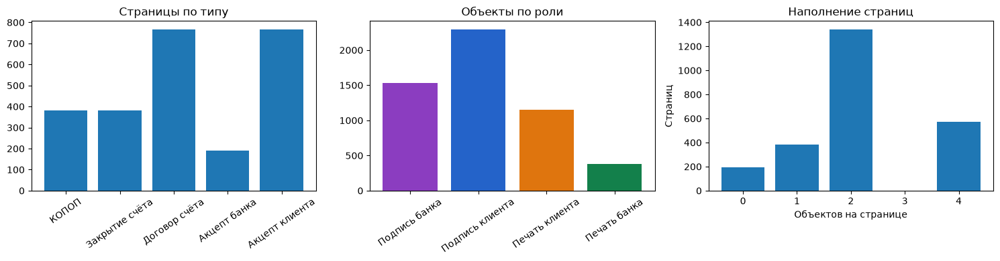

In [2]:
family_counts = Counter(r["family"] for r in prows)
role_counts = Counter(o["class_id"] for o in pobjects)
negative = sum(not r["objects"] for r in prows)
assert len(prows) == psummary["pages"] and len(pobjects) == psummary["objects"]
ptable(
    [
        {"Тип документа": FAMILY_LABELS[k], "Страниц": v}
        for k, v in sorted(family_counts.items())
    ],
    "01_families",
)
ptable(
    [{"Объект": ROLE_LABELS[k], "Вставок": v} for k, v in sorted(role_counts.items())],
    "01_roles",
)
ptable(
    [
        {"Вариант страницы": k, "Страниц": v}
        for k, v in sorted(Counter(r["template_id"] for r in prows).items())
    ],
    "01_page_templates",
)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar([FAMILY_LABELS[k] for k in family_counts], list(family_counts.values()))
axes[0].tick_params(axis="x", rotation=35)
axes[0].set_title("Страницы по типу")
axes[1].bar(
    [ROLE_LABELS[k] for k in role_counts],
    list(role_counts.values()),
    color=[PCOLORS[k] for k in role_counts],
)
axes[1].tick_params(axis="x", rotation=35)
axes[1].set_title("Объекты по роли")
cc = Counter(len(r["objects"]) for r in prows)
axes[2].bar(list(cc), list(cc.values()))
axes[2].set(xlabel="Объектов на странице", ylabel="Страниц", title="Наполнение страниц")
pfig(fig, "01_composition")
pres["composition"] = {
    "pages": len(prows),
    "objects": len(pobjects),
    "families": dict(family_counts),
    "roles": dict(role_counts),
    "negative_pages": negative,
    "packets": len(ppackets),
}
pnotes["1"] = (
    f"В наборе {len(prows)} страниц и {len(pobjects)} вставок, "
    f"страниц без объектов {negative} "
    f"({negative / len(prows):.1%}). Типов макетов пять; "
    f"распределение отражает структуру сгенерированных "
    f"комплектов, а не частоты банковского потока."
)

**Результат и вывод.** В наборе 2493 страницы и 5366 вставок, 192 страницы без объектов (7.7%). Пять типов макетов и их частоты отражают структуру синтетических комплектов, а не банковский поток.

## Страницы 2. Целостность данных и разметки

Проверяем все активные изображения, labels и alpha, хеши и границы. Сверяем рамки с чернилами и учитываем карантин. Проверка выполняется заново, а не только читается из готового отчёта.

In [3]:
paudit = Counter()
pixel_hashes = []
perceptual = []
active_paths = set()
actual_alpha = set()
for i, r in enumerate(prows):
    path = PAGE_DATA / r["image_path"]
    remember(path)
    image = pim(path)
    hh, ww = image.shape[:2]
    assert [ww, hh] == r["image_size_wh"] == [1654, 2339]
    assert phashfile(path) == r["image_sha256"]
    pixel = hashlib.sha256(cv2.cvtColor(image, cv2.COLOR_BGR2RGB).tobytes()).hexdigest()
    assert pixel == r["pixel_sha256"]
    pixel_hashes.append(pixel)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    dct = cv2.dct(
        cv2.resize(gray, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    )[:8, :8].ravel()[1:]
    perceptual.append(
        int.from_bytes(np.packbits(dct > np.median(dct)).tobytes(), "big")
    )
    lp = PAGE_DATA / "labels" / f"{r['page_id']}.txt"
    remember(lp)
    label = lp.read_text().splitlines()
    assert len(label) == len(r["objects"])
    for o, line in zip(r["objects"], label):
        ap = PAGE_DATA / o["alpha_path"]
        remember(ap)
        a = pim(ap, cv2.IMREAD_GRAYSCALE) / 255
        actual_alpha.add(o["alpha_path"])
        yy, xx = np.where(a > 0.12)
        assert len(xx)
        x, y = o["alpha_origin_xy"]
        derived = [x + xx.min(), y + yy.min(), x + xx.max() + 1, y + yy.max() + 1]
        assert max(abs(v - t) for v, t in zip(derived, o["bbox_xyxy"])) <= 1
        x1, y1, x2, y2 = o["bbox_xyxy"]
        assert 0 <= x1 < x2 <= ww and 0 <= y1 < y2 <= hh
        cls, cx, cy, bw, bh = map(float, line.split())
        assert int(cls) == o["class_id"]
        assert (
            max(
                abs(v - t)
                for v, t in zip(
                    [cx, cy, bw, bh],
                    [
                        (x1 + x2) / ww / 2,
                        (y1 + y2) / hh / 2,
                        (x2 - x1) / ww,
                        (y2 - y1) / hh,
                    ],
                )
            )
            < 1e-6
        )
        paudit["objects"] += 1
        paudit["empty_masks"] += int(not (a > 0.3).any())
        paudit["page_edge_contacts"] += int(x1 == 0 or y1 == 0 or x2 == ww or y2 == hh)
        paudit["beyond_scale_policy"] += int(
            o["scale_no_upscale"] > (1 if o["kind"] == "signature" else 1.5) + 1e-6
        )
    paudit["pages"] += 1
    if (i + 1) % 600 == 0:
        print(f"Проверено {i + 1}/{len(prows)} страниц")
assert {p.stem for p in (PAGE_DATA / "images").glob("*.png")} == set(pbyid)
assert {p.stem for p in (PAGE_DATA / "labels").glob("*.txt")} == set(pbyid)
assert {
    str(p.relative_to(PAGE_DATA)).replace("\\", "/")
    for p in (PAGE_DATA / "object_alpha").glob("*.png")
} == actual_alpha
for relative, digest in pj(PAGE_DATA / "source_hashes.json").items():
    path = ROOT / relative
    remember(path)
    assert phashfile(path) == digest
excluded = set(pexclusion["excluded_page_ids"])
assert not excluded.intersection(pbyid)
paudit["exact_pixel_duplicates"] = len(pixel_hashes) - len(set(pixel_hashes))
paudit["excluded_pages"] = len(excluded)
ptable([{"Проверка": k, "Количество": v} for k, v in paudit.items()], "02_integrity")
pres["integrity"] = dict(paudit)
pnotes["2"] = (
    f"Повторно проверены {paudit['pages']} страниц и "
    f"{paudit['objects']} объектов: точных пиксельных дублей "
    f"{paudit['exact_pixel_duplicates']}, пустых масок "
    f"{paudit['empty_masks']}, касаний края "
    f"{paudit['page_edge_contacts']}. Три исключённые страницы "
    f"отсутствуют в активных данных; геометрия и хеши корректны. "
    f"Это техническая целостность, не гарантия естественности "
    f"каждой подписи."
)

Проверено 600/2493 страниц
Проверено 1200/2493 страниц
Проверено 1800/2493 страниц
Проверено 2400/2493 страниц


Проверка,Количество
objects,5366
empty_masks,0
page_edge_contacts,0
beyond_scale_policy,0
pages,2493
exact_pixel_duplicates,0
excluded_pages,3


**Результат и вывод.** Повторно проверены все 2493 страницы и 5366 объектов: точных пиксельных дублей, пустых масок и касаний края нет; хеши и геометрия корректны. Три исключённые страницы отсутствуют в активных данных. Техническая целостность не гарантирует естественность каждой вставки.

## Общие измерения для блоков 4–7 и 9

Для каждой вставки измеряем маску и положение, читаем чистый бланк той же страницы для отделения печатного фона от чернил.
Линии выделяем длинными горизонтальными/вертикальными элементами на 13 чистых макетах; «текст» ниже — оставшиеся тёмные пиксели, а не результат OCR.
Толщина по distance transform дискретна; признаки служат диагностикой. Маски описывают скрытые чернила, включая пересечения, а не только видимую часть объекта.

In [4]:
line_masks = {}
for template in sorted({r["template_id"] for r in prows}):
    fp = (
        ROOT
        / "data/templates/neutral_v1/pages"
        / (
            "page-"
            + "{:02d}".format(
                next(
                    p["pdf_page"]
                    for p in pj(
                        ROOT / "data/templates/neutral_v1/template_manifest.json"
                    )["pages"]
                    if p["page_id"] == template
                )
            )
            + ".png"
        )
    )
    remember(fp)
    b = (pim(fp, cv2.IMREAD_GRAYSCALE) < 180).astype(np.uint8)
    lines = cv2.morphologyEx(
        b, cv2.MORPH_OPEN, np.ones((1, 65), np.uint8)
    ) | cv2.morphologyEx(b, cv2.MORPH_OPEN, np.ones((65, 1), np.uint8))
    line_masks[template] = cv2.dilate(lines, np.ones((3, 3), np.uint8)).astype(bool)


def intersection_slices(o, a, other, b):
    x, y = o["alpha_origin_xy"]
    xx, yy = other["alpha_origin_xy"]
    left = max(x, xx)
    top = max(y, yy)
    right = min(x + a.shape[1], xx + b.shape[1])
    bottom = min(y + a.shape[0], yy + b.shape[0])
    if right <= left or bottom <= top:
        return None
    return (slice(top - y, bottom - y), slice(left - x, right - x)), (
        slice(top - yy, bottom - yy),
        slice(left - xx, right - xx),
    )


overlap_pairs = []
for i, r in enumerate(prows):
    image = pim(PAGE_DATA / r["image_path"])
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255
    blank_path = (
        ROOT
        / "tmp/pdfs/page_dataset_v1/render"
        / f"page-{playout_by[r['page_id']]['pdf_page']:04d}.png"
    )
    assert blank_path.is_file(), "Нужны чистые рендеры для анализа печатного фона"
    remember(blank_path)
    blank = pim(blank_path, cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255
    alphas = {
        o["id"]: pim(PAGE_DATA / o["alpha_path"], cv2.IMREAD_GRAYSCALE).astype(
            np.float32
        )
        / 255
        for o in r["objects"]
    }
    for o in r["objects"]:
        a = alphas[o["id"]]
        b = a > 0.3
        yy, xx = o["alpha_origin_xy"][1], o["alpha_origin_xy"][0]
        h, w = a.shape
        other_ink = np.zeros_like(b)
        for other in r["objects"]:
            if other["id"] == o["id"]:
                continue
            bb = alphas[other["id"]]
            sl = intersection_slices(o, a, other, bb)
            if sl is not None:
                other_ink[sl[0]] |= bb[sl[1]] > 0.3
        bp = blank[yy : yy + h, xx : xx + w]
        gp = gray[yy : yy + h, xx : xx + w]
        lm = line_masks[r["template_id"]][yy : yy + h, xx : xx + w]
        dark = bp < 0.7
        clear = b & (bp > 0.9) & (~other_ink)
        stats = pstats(a)
        x1, y1, x2, y2 = o["bbox_xyxy"]
        den = max(1, int(b.sum()))
        pmeasure.append(
            dict(
                id=o["id"],
                page_id=r["page_id"],
                packet_id=r["packet_id"],
                kind=o["kind"],
                actor=o["actor"],
                class_id=o["class_id"],
                source_id=o["source_id"],
                identity=o["identity"],
                seal_guard_group=o["seal_guard_group"],
                family=r["family"],
                template_id=r["template_id"],
                width_px=x2 - x1,
                height_px=y2 - y1,
                min_side_px=min(x2 - x1, y2 - y1),
                area_fraction=(x2 - x1) * (y2 - y1) / (1654 * 2339),
                aspect=(x2 - x1) / (y2 - y1),
                cx=(x1 + x2) / 3308,
                cy=(y1 + y2) / 4678,
                scale=o["scale_no_upscale"],
                rotation=o["rotation_deg"],
                color="_".join(f"{v:.2f}" for v in o["ink_rgb"]),
                fill_fraction=float(b.mean()),
                alpha_p95=float(np.percentile(a[a > 0.02], 95)),
                contrast_drop=float(np.median(bp[clear] - gp[clear]))
                if clear.any()
                else None,
                clear_pixels=int(clear.sum()),
                overlap_other=float((b & other_ink).sum() / den),
                overlap_print=float((b & dark).sum() / den),
                overlap_lines=float((b & lm).sum() / den),
                overlap_text_proxy=float((b & dark & (~lm)).sum() / den),
                **stats,
            )
        )
    for o, other in combinations(r["objects"], 2):
        if o["kind"] == other["kind"]:
            continue
        a = alphas[o["id"]]
        b = alphas[other["id"]]
        sl = intersection_slices(o, a, other, b)
        overlap = (
            int(((a[sl[0]] > 0.3) & (b[sl[1]] > 0.3)).sum()) if sl is not None else 0
        )
        overlap_pairs.append(
            {
                "page_id": r["page_id"],
                "first": o["id"],
                "second": other["id"],
                "intersection_ink_pixels": overlap,
                "same_color": bool(np.allclose(o["ink_rgb"], other["ink_rgb"])),
                "color_distance_rgb": float(
                    np.linalg.norm(np.array(o["ink_rgb"]) - other["ink_rgb"])
                ),
            }
        )
    if (i + 1) % 600 == 0:
        print(f"Измерено {i + 1}/{len(prows)} страниц")
psave("object_measurements.json", pmeasure)
psave("overlap_pairs.json", overlap_pairs)
pmby = {m["id"]: m for m in pmeasure}
print(
    f"Измерено {len(pmeasure)} объектов; пар подпись–печать для "
    f"диагностики {len(overlap_pairs)}."
)

Измерено 600/2493 страниц
Измерено 1200/2493 страниц
Измерено 1800/2493 страниц
Измерено 2400/2493 страниц
Измерено 5366 объектов; пар подпись–печать для диагностики 2682.


## Страницы 3. Разнообразие и повторы

Считаем частоты использования людей, естественных сканов и шаблонов. Проверяем уникальность реквизитов комплектов и сходство страниц по pHash; совпадение pHash не считаем точным дублем или совпадением identity.

Шаблон печати,Вставок
c0011,96
c0030,96
c0089,48
c0090,48
c0148,96
c0203,96
c0257,95
c0324,96
c0359,95
c0406,96


Страница A,Страница B,pHash distance /63
pkt_0001__N01_p01,pkt_0003__N01_p01,0
pkt_0001__N01_p02,pkt_0065__N01_p02,0
pkt_0001__N04_p01,pkt_0017__N04_p01,0


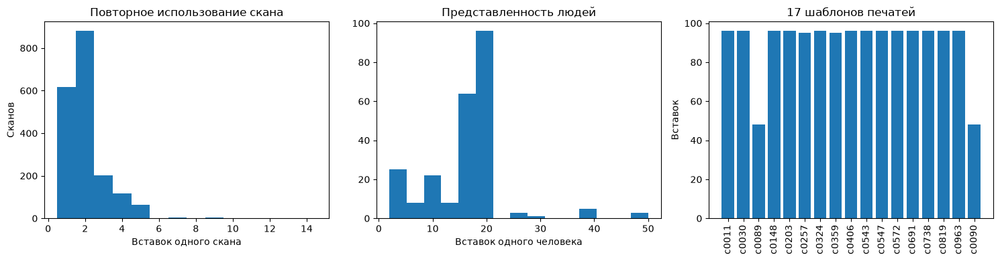

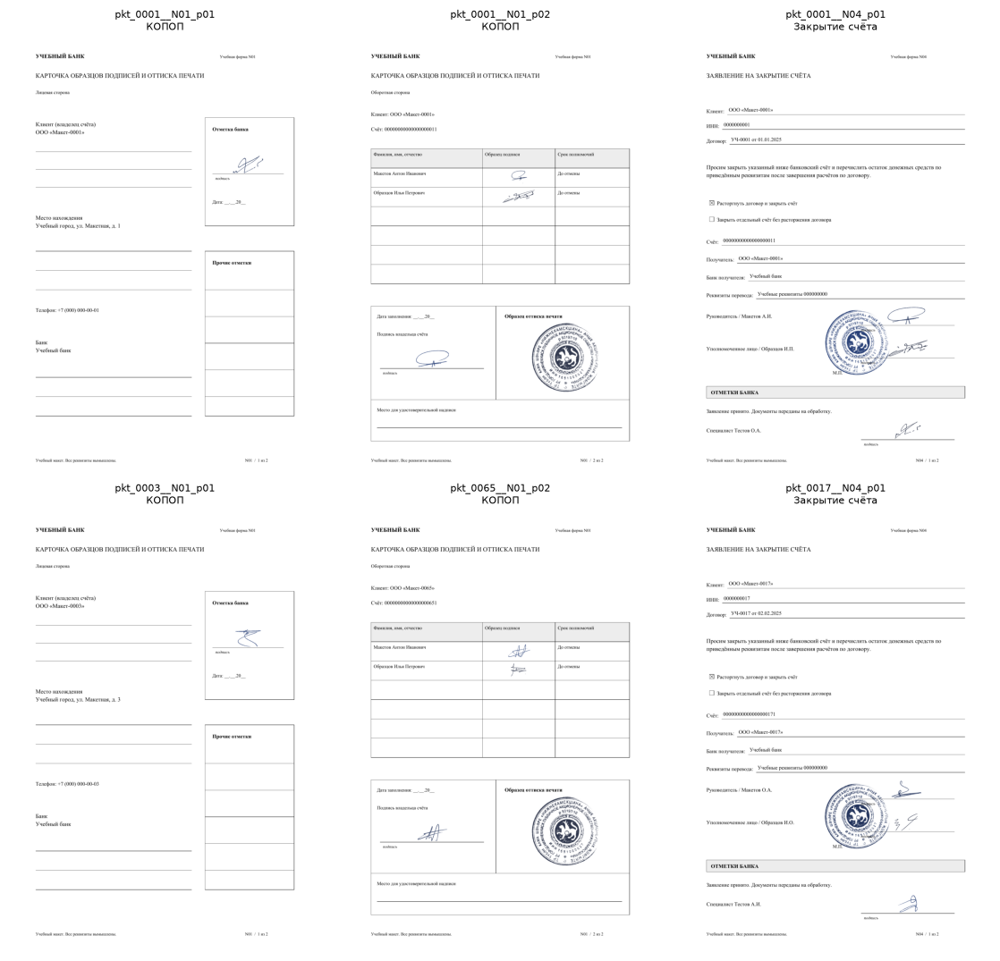

In [5]:
source_uses = Counter(o["source_id"] for o in pobjects if o["kind"] == "signature")
writer_uses = Counter(o["identity"] for o in pobjects if o["kind"] == "signature")
seal_uses = Counter(o["source_id"] for o in pobjects if o["kind"] == "stamp")
seal_groups = Counter(o["seal_guard_group"] for o in pobjects if o["kind"] == "stamp")
ptable(
    [{"Шаблон печати": k, "Вставок": v} for k, v in sorted(seal_uses.items())],
    "03_seal_reuse",
)
profile_unique = len({p["company"] for p in ppackets})
assert profile_unique == len(ppackets)
ph_buckets = Counter(perceptual)
ph_equal_pairs = sum(n * (n - 1) // 2 for n in ph_buckets.values())
near = []
for i in range(len(prows)):
    candidates = [
        ((perceptual[i] ^ perceptual[j]).bit_count(), j)
        for j in range(i + 1, len(prows))
        if prows[i]["packet_id"] != prows[j]["packet_id"]
    ]
    if candidates:
        distance, j = min(candidates)
        near.append((distance, i, j))
near.sort()
unique_pairs = []
seen_templates = set()
for distance, i, j in near:
    pair = (prows[i]["template_id"], prows[j]["template_id"])
    if pair in seen_templates:
        continue
    unique_pairs.append((distance, i, j))
    seen_templates.add(pair)
    if len(unique_pairs) == 3:
        break
ptable(
    [
        {
            "Страница A": prows[i]["page_id"],
            "Страница B": prows[j]["page_id"],
            "pHash distance /63": d,
        }
        for d, i, j in unique_pairs
    ],
    "03_similar_pages",
)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(
    list(source_uses.values()), bins=np.arange(1, max(source_uses.values()) + 2) - 0.5
)
axes[0].set(
    title="Повторное использование скана",
    xlabel="Вставок одного скана",
    ylabel="Сканов",
)
axes[1].hist(list(writer_uses.values()), bins=15)
axes[1].set(title="Представленность людей", xlabel="Вставок одного человека")
axes[2].bar(list(seal_uses), list(seal_uses.values()))
axes[2].tick_params(axis="x", rotation=90)
axes[2].set(title="17 шаблонов печатей", ylabel="Вставок")
pfig(fig, "03_source_reuse")
page_grid(
    [prows[i] for _, i, j in unique_pairs] + [prows[j] for _, i, j in unique_pairs],
    "03_similar_page_examples",
    cols=3,
    boxes=False,
)
pres["diversity"] = {
    "signature_people": len(writer_uses),
    "natural_signature_scans": len(source_uses),
    "seal_templates": len(seal_uses),
    "seal_groups": len(seal_groups),
    "max_scan_reuse": max(source_uses.values()),
    "unique_fictional_companies": profile_unique,
    "phash_equal_pairs": ph_equal_pairs,
    "phash_definition": "63 DCT coefficients, no DC; structural similarity only",
}
pnotes["3"] = (
    f"Использованы {len(source_uses)} естественных сканов от "
    f"{len(writer_uses)} людей и {len(seal_uses)} шаблонов / "
    f"{len(seal_groups)} групп печатей. Один скан встречается до "
    f"{max(source_uses.values())} раз; компании всех "
    f"{profile_unique} комплектов различаются. pHash совпал у "
    f"{ph_equal_pairs} пар страниц: это ожидаемая повторяемость "
    f"макетов, не точные пиксельные дубли и не независимые "
    f"документы."
)

**Результат и вывод.** Использованы 1888 естественных сканов от 235 людей и 17 шаблонов / 16 групп печатей. Один скан встречается до 14 раз; компании всех 192 комплектов различаются. pHash совпал у 49220 пар страниц: это ожидаемая повторяемость макетов, не точные пиксельные дубли и не независимые документы.

## Страницы 4. Размеры и положение объектов

Измеряем размеры рамок, пропорции и долю площади страницы по четырём ролям. Смотрим крайние значения и пространственное распределение только как характеристику синтетики, не как бизнес-проверку расположения.

Объект,Количество,"Медиана ширины, px","Медиана высоты, px","Минимальная короткая сторона, px","Медиана площади страницы, %"
Подпись клиента,2298,145.0,90.0,53,0.345
Печать клиента,1150,305.0,305.5,194,2.412
Подпись банка,1534,150.0,90.0,53,0.374
Печать банка,384,278.0,277.5,194,2.017


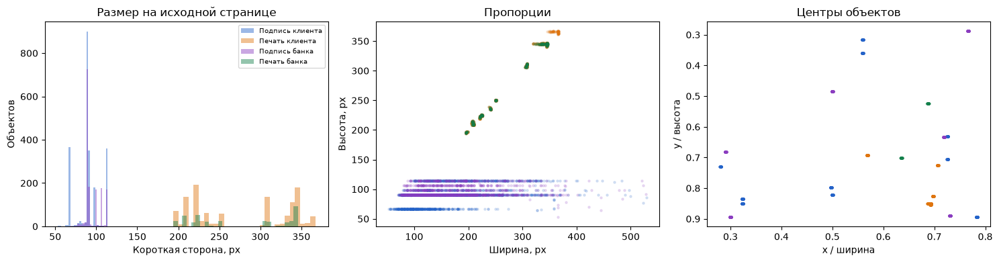

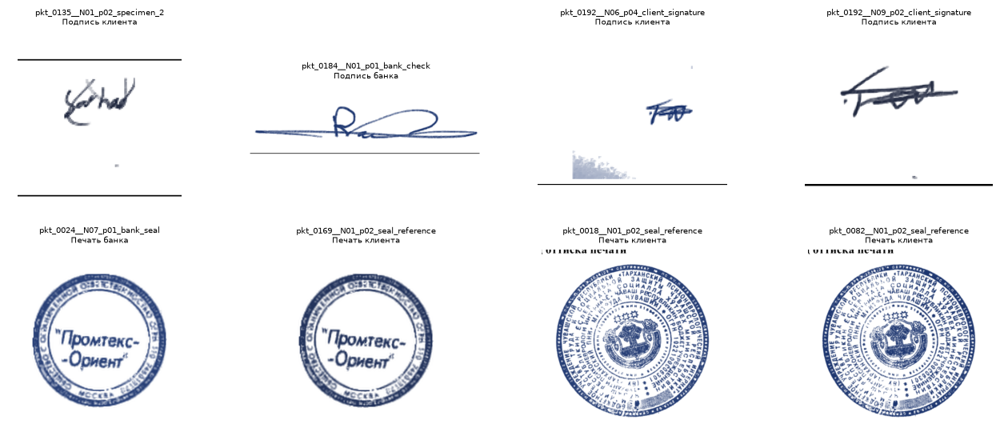

In [6]:
geometry = []
for cls in range(4):
    group = [m for m in pmeasure if m["class_id"] == cls]
    v = np.array(
        [
            [m["width_px"], m["height_px"], m["min_side_px"], m["area_fraction"]]
            for m in group
        ]
    )
    geometry.append(
        {
            "Объект": ROLE_LABELS[cls],
            "Количество": len(group),
            "Медиана ширины, px": round(float(np.median(v[:, 0])), 1),
            "Медиана высоты, px": round(float(np.median(v[:, 1])), 1),
            "Минимальная короткая сторона, px": int(v[:, 2].min()),
            "Медиана площади страницы, %": round(float(np.median(v[:, 3]) * 100), 3),
        }
    )
ptable(geometry, "04_geometry")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for cls in range(4):
    g = [m for m in pmeasure if m["class_id"] == cls]
    axes[0].hist(
        [m["min_side_px"] for m in g],
        bins=28,
        alpha=0.45,
        color=PCOLORS[cls],
        label=ROLE_LABELS[cls],
    )
    axes[1].scatter(
        [m["width_px"] for m in g],
        [m["height_px"] for m in g],
        s=5,
        alpha=0.15,
        color=PCOLORS[cls],
    )
    axes[2].scatter(
        [m["cx"] for m in g], [m["cy"] for m in g], s=4, alpha=0.12, color=PCOLORS[cls]
    )
axes[0].set(
    xlabel="Короткая сторона, px",
    ylabel="Объектов",
    title="Размер на исходной странице",
)
axes[0].legend(fontsize=7)
axes[1].set(xlabel="Ширина, px", ylabel="Высота, px", title="Пропорции")
axes[2].set(xlabel="x / ширина", ylabel="y / высота", title="Центры объектов")
axes[2].invert_yaxis()
pfig(fig, "04_geometry_and_positions")
extreme = []
for kind in ("signature", "stamp"):
    group = sorted(
        (m for m in pmeasure if m["kind"] == kind), key=lambda m: m["min_side_px"]
    )
    extreme.extend([pobject_by[m["id"]] for m in group[:2] + group[-2:]])
object_grid(extreme, "04_size_extremes")
pres["geometry"] = {
    "roles": geometry,
    "min_signature_side_px": min(
        m["min_side_px"] for m in pmeasure if m["kind"] == "signature"
    ),
}
pnotes["4"] = (
    f"Минимальная короткая сторона подписи на исходной странице — "
    f"{pres['geometry']['min_signature_side_px']} px. Размеры "
    f"подписей и печатей существенно различаются; центры "
    f"повторяют структуру макетов. Фиксированные места могут "
    f"стать подсказкой детектору и не доказывают переносимость на "
    f"другие бланки."
)

**Результат и вывод.** Минимальная короткая сторона подписи на исходной странице — 53 px. Размеры подписей и печатей существенно различаются; центры повторяют структуру макетов. Фиксированные места могут стать подсказкой детектору и не доказывают переносимость на другие бланки.

## Страницы 5. Детали при уменьшении страницы

Диагностически рассматриваем длинную сторону 640/960/1280/1600 px. Для всех масок оцениваем размер, штрихи и компоненты после area-уменьшения; для примеров уменьшаем целую страницу. Это не выбор размера модели и не её метрика.

Объект,Длинная сторона страницы,"Медиана короткой стороны объекта, px","Короткая сторона <16px, %","Исчезла сильная маска, %","Резкий рост компонент, %","Медиана толщины, px"
Подпись,640,24.6,0.18,0.0,3.16,1.91
Подпись,960,36.9,0.0,0.0,0.16,1.91
Подпись,1280,49.3,0.0,0.0,0.0,1.91
Подпись,1600,61.6,0.0,0.0,0.0,1.91
Печать,640,83.5,0.0,0.0,0.0,1.91
Печать,960,125.2,0.0,0.0,0.0,1.91
Печать,1280,166.9,0.0,0.0,0.0,1.91
Печать,1600,208.6,0.0,0.0,0.0,2.74


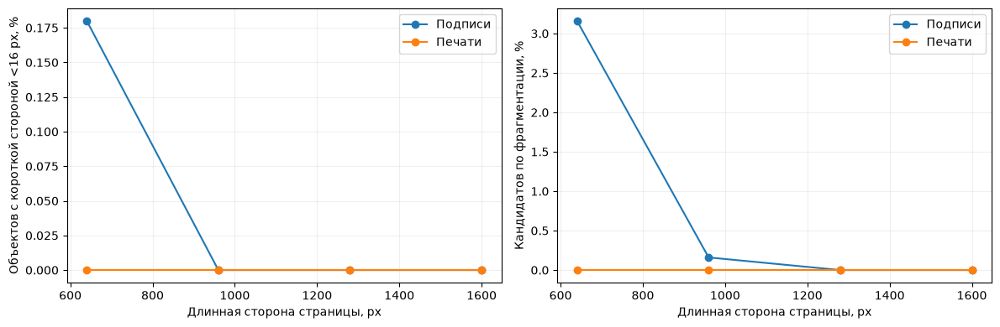

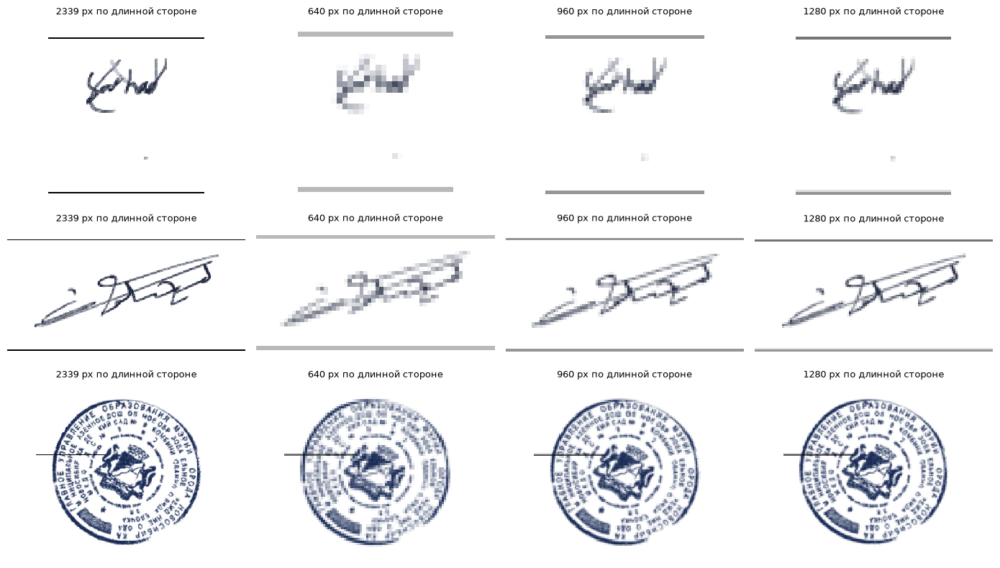

In [7]:
sizes = (640, 960, 1280, 1600)
for o in pobjects:
    a = pim(PAGE_DATA / o["alpha_path"], cv2.IMREAD_GRAYSCALE).astype(np.float32) / 255
    baseline = pmby[o["id"]]
    for side in sizes:
        scale = side / 2339
        resized = cv2.resize(
            a,
            (max(1, round(a.shape[1] * scale)), max(1, round(a.shape[0] * scale))),
            interpolation=cv2.INTER_AREA,
        )
        stats = pstats(resized)
        presize.append(
            {
                "id": o["id"],
                "kind": o["kind"],
                "long_side": side,
                "short_side_px": baseline["min_side_px"] * scale,
                "empty_strong_mask": stats["ink_pixels"] == 0,
                "fragment_growth": stats["components"]
                > max(8, 2 * baseline["components"]),
                "component_retention": stats["components"]
                / max(1, baseline["components"]),
                "stroke_px": stats["stroke_px"],
                "ink_pixels": stats["ink_pixels"],
            }
        )
resize_summary = []
for kind in ("signature", "stamp"):
    for side in sizes:
        g = [m for m in presize if m["kind"] == kind and m["long_side"] == side]
        resize_summary.append(
            {
                "Объект": "Подпись" if kind == "signature" else "Печать",
                "Длинная сторона страницы": side,
                "Медиана короткой стороны объекта, px": round(
                    float(np.median([m["short_side_px"] for m in g])), 1
                ),
                "Короткая сторона <16px, %": round(
                    100 * np.mean([m["short_side_px"] < 16 for m in g]), 2
                ),
                "Исчезла сильная маска, %": round(
                    100 * np.mean([m["empty_strong_mask"] for m in g]), 3
                ),
                "Резкий рост компонент, %": round(
                    100 * np.mean([m["fragment_growth"] for m in g]), 2
                ),
                "Медиана толщины, px": round(
                    float(np.median([m["stroke_px"] for m in g])), 2
                ),
            }
        )
ptable(resize_summary, "05_resize")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind, label in [("signature", "Подписи"), ("stamp", "Печати")]:
    g = [
        r
        for r in resize_summary
        if r["Объект"] == ("Подпись" if kind == "signature" else "Печать")
    ]
    axes[0].plot(
        sizes, [r["Короткая сторона <16px, %"] for r in g], marker="o", label=label
    )
    axes[1].plot(
        sizes, [r["Резкий рост компонент, %"] for r in g], marker="o", label=label
    )
for ax in axes:
    ax.set_xlabel("Длинная сторона страницы, px")
    ax.legend()
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Объектов с короткой стороной <16 px, %")
axes[1].set_ylabel("Кандидатов по фрагментации, %")
pfig(fig, "05_resize_diagnostics")
chosen = [
    pobject_by[
        min(
            (m for m in pmeasure if m["kind"] == "signature"),
            key=lambda m: m["min_side_px"],
        )["id"]
    ],
    pobject_by[
        min(
            (m for m in pmeasure if m["kind"] == "signature"),
            key=lambda m: m["stroke_px"],
        )["id"]
    ],
    pobject_by[
        max((m for m in pmeasure if m["kind"] == "stamp"), key=lambda m: m["scale"])[
            "id"
        ]
    ],
]
fig, axes = plt.subplots(len(chosen), 4, figsize=(14, 8), squeeze=False)
for rr, o in enumerate(chosen):
    image = cv2.cvtColor(
        pim(PAGE_DATA / pbyid[o["page_id"]]["image_path"]), cv2.COLOR_BGR2RGB
    )
    a, b, c, d = o["bbox_xyxy"]
    pad = 25
    for col, side in enumerate((2339, 640, 960, 1280)):
        scale = side / 2339
        im = cv2.resize(
            image, (round(1654 * scale), side), interpolation=cv2.INTER_AREA
        )
        aa, bb, cc, dd = (
            round(v * scale)
            for v in [
                max(0, a - pad),
                max(0, b - pad),
                min(1654, c + pad),
                min(2339, d + pad),
            ]
        )
        axes[rr, col].imshow(
            im[bb : max(bb + 1, dd), aa : max(aa + 1, cc)], interpolation="nearest"
        )
        axes[rr, col].axis("off")
        axes[rr, col].set_title(f"{side} px по длинной стороне", fontsize=9)
    axes[rr, 0].set_ylabel(o["id"], fontsize=7)
pfig(fig, "05_resize_examples")
psave("resize_measurements.json", presize)
pres["resize"] = {
    "summary": resize_summary,
    "sizes": sizes,
    "method": (
        "local alpha area-resize approximate; global-page examples "
        "are exact isotropic page resize, no model tested"
    ),
}
s640 = next(
    r
    for r in resize_summary
    if r["Объект"] == "Подпись" and r["Длинная сторона страницы"] == 640
)
s1280 = next(
    r
    for r in resize_summary
    if r["Объект"] == "Подпись" and r["Длинная сторона страницы"] == 1280
)
pnotes["5"] = (
    f"При длинной стороне 640 px короткая сторона меньше 16 px у "
    f"{s640['Короткая сторона <16px, %']}% подписей; при 1280 px "
    f"— у {s1280['Короткая сторона <16px, %']}%. Это "
    f"диагностический ориентир, не граница брака. Компоненты "
    f"считаются с порогом площади 3 px на каждом масштабе, "
    f"толщина дискретна; результат надо оценивать вместе с "
    f"примерами."
)

**Результат и вывод.** При 640 px по длинной стороне резкий рост числа компонент наблюдается у 3.16% подписей, при 960 px — у 0.16%, при 1280 px — у 0.0%. Визуальные примеры показывают потерю деталей при уменьшении; ноль по диагностике не означает полного сохранения рисунка. Порог площади компонент и дискретность толщины ограничивают метод; размер входа модели не выбран.

## Страницы 6. Качество чернил и масштабирование

Смотрим контраст, толщину, связность и коэффициенты масштабирования. Контраст — падение яркости относительно чистого бланка на неперекрытых чернилах; разные масштабы исходника и вставки показываем отдельно. Автоматический порог брака не задаём.

Объект,"Медиана толщины, px",Медиана падения яркости 0–1,Нет чистых пикселей для контраста,Увеличение растра >1,Максимальный масштаб
signature,2.74,0.627,0,0,1
stamp,3.82,0.596,0,1162,1.5


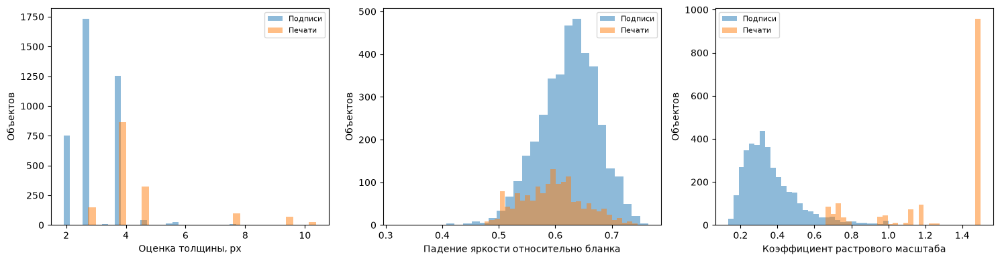

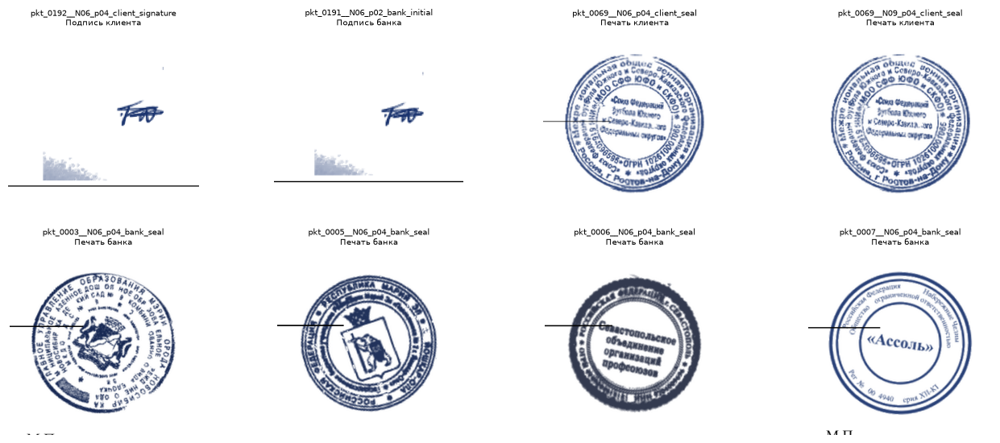

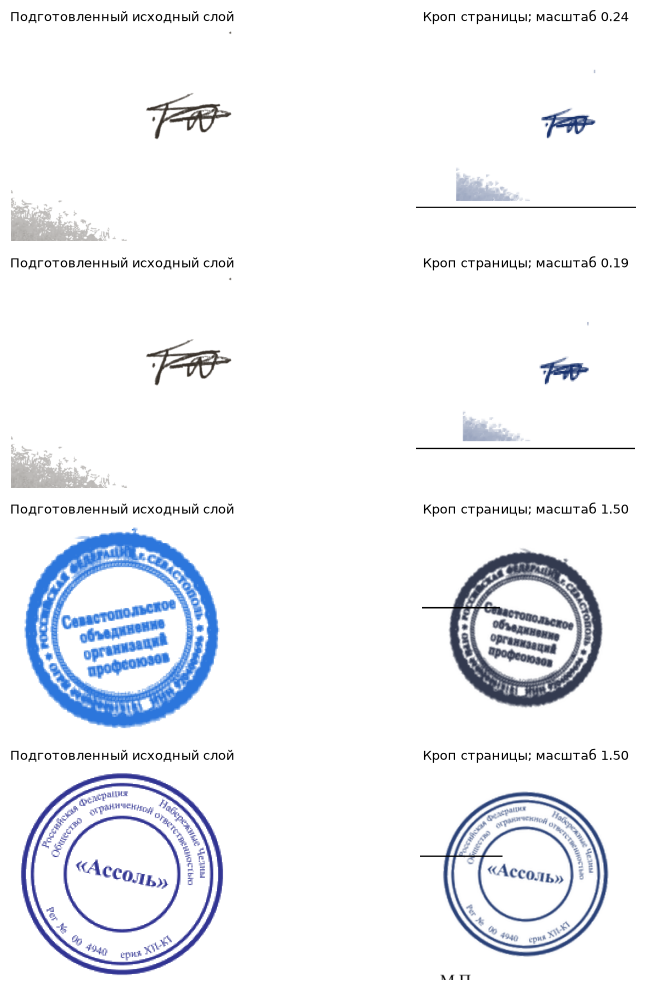

In [8]:
quality = []
for kind in ("signature", "stamp"):
    g = [m for m in pmeasure if m["kind"] == kind]
    valid = [m["contrast_drop"] for m in g if m["contrast_drop"] is not None]
    quality.append(
        {
            "Объект": kind,
            "Медиана толщины, px": round(
                float(np.median([m["stroke_px"] for m in g])), 2
            ),
            "Медиана падения яркости 0–1": round(float(np.median(valid)), 3),
            "Нет чистых пикселей для контраста": len(g) - len(valid),
            "Увеличение растра >1": sum(m["scale"] > 1 for m in g),
            "Максимальный масштаб": round(max(m["scale"] for m in g), 3),
        }
    )
ptable(quality, "06_quality")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for kind, label in [("signature", "Подписи"), ("stamp", "Печати")]:
    g = [m for m in pmeasure if m["kind"] == kind]
    axes[0].hist([m["stroke_px"] for m in g], bins=30, alpha=0.5, label=label)
    axes[1].hist(
        [m["contrast_drop"] for m in g if m["contrast_drop"] is not None],
        bins=30,
        alpha=0.5,
        label=label,
    )
    axes[2].hist([m["scale"] for m in g], bins=30, alpha=0.5, label=label)
for ax in axes:
    ax.legend(fontsize=8)
    ax.set_ylabel("Объектов")
axes[0].set_xlabel("Оценка толщины, px")
axes[1].set_xlabel("Падение яркости относительно бланка")
axes[2].set_xlabel("Коэффициент растрового масштаба")
pfig(fig, "06_ink_quality")
quality_ids = []
for kind in ("signature", "stamp"):
    g = sorted(
        (m for m in pmeasure if m["kind"] == kind),
        key=lambda m: (
            m["contrast_drop"] if m["contrast_drop"] is not None else 99,
            m["stroke_px"],
        ),
    )
    quality_ids.extend([pobject_by[m["id"]] for m in g[:2]])
for m in sorted(
    (m for m in pmeasure if m["kind"] == "stamp"), key=lambda m: -m["scale"]
):
    if m["source_id"] not in [
        o["source_id"] for o in quality_ids if o["kind"] == "stamp"
    ]:
        quality_ids.append(pobject_by[m["id"]])
    if len(quality_ids) >= 8:
        break
object_grid(quality_ids, "06_quality_extremes")
fig, axes = plt.subplots(4, 2, figsize=(10, 10))
compare = quality_ids[:2] + [o for o in quality_ids if o["kind"] == "stamp"][-2:]
for rr, o in enumerate(compare):
    layer = pim(ROOT / o["source_path"], cv2.IMREAD_UNCHANGED)
    a = layer[:, :, 3:4].astype(float) / 255
    rgb = cv2.cvtColor(layer[:, :, :3], cv2.COLOR_BGR2RGB)
    white = (rgb * a + 255 * (1 - a)).astype(np.uint8)
    axes[rr, 0].imshow(white)
    axes[rr, 1].imshow(object_crop(o))
    axes[rr, 0].set_title("Подготовленный исходный слой", fontsize=9)
    axes[rr, 1].set_title(
        f"Кроп страницы; масштаб {pmby[o['id']]['scale']:.2f}", fontsize=9
    )
    for ax in axes[rr]:
        ax.axis("off")
pfig(fig, "06_source_vs_page")
pres["quality"] = {
    "summary": quality,
    "diagnostic_object_ids": [o["id"] for o in quality_ids],
    "contrast_caveat": (
        "paper-only target pixels excluding other ink; not a human legibility score"
    ),
}
stamp_quality = next(r for r in quality if r["Объект"] == "stamp")
pnotes["6"] = (
    f"Увеличение исходного растра применено к "
    f"{stamp_quality['Увеличение растра >1']} вставкам печатей, "
    f"максимум {stamp_quality['Максимальный масштаб']}×; все 17 "
    f"шаблонов сохранены. Усиление/интерполяция не "
    f"восстанавливает отсутствующие штрихи. Крайние случаи "
    f"показаны отдельно; численные показатели не заменяют оценку "
    f"читаемости."
)

**Результат и вывод.** Увеличены 1162 вставки печатей, максимум 1.5×; все 17 шаблонов сохранены. В одном подготовленном слое подписи визуально подтверждён остаток фона, повторённый в двух вставках (показаны в примерах). Это новая находка EDA для очистки или исключения после согласования; сейчас данные не менялись.

## Страницы 7. Наложения

По сильным пикселям alpha считаем пересечения с другими чернилами, линиями и тёмным печатным фоном. Отдельно смотрим цвет пары подпись–печать и сложные примеры; пересечение не равно полной невидимости.

Пар с пересечением чернил: 45; из них одинаковый цвет: 18.


Объект,"Есть пересечение с другими чернилами, %","Пересечение >10% чернил, %","Есть пересечение с линиями, %","Есть пересечение с тёмным текстовым фоном, %"
signature,1.17,0.03,0.0,0.0
stamp,2.93,0.0,56.06,12.71


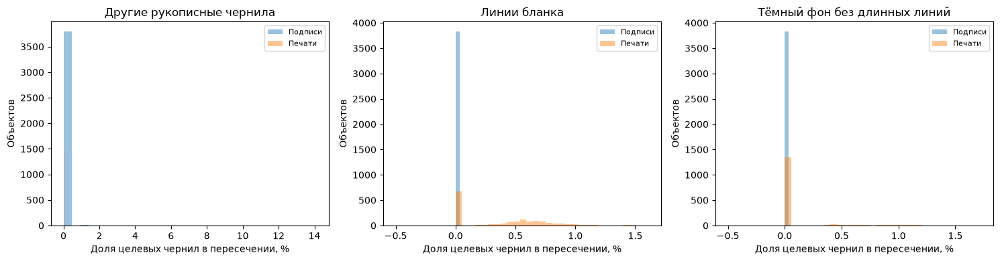

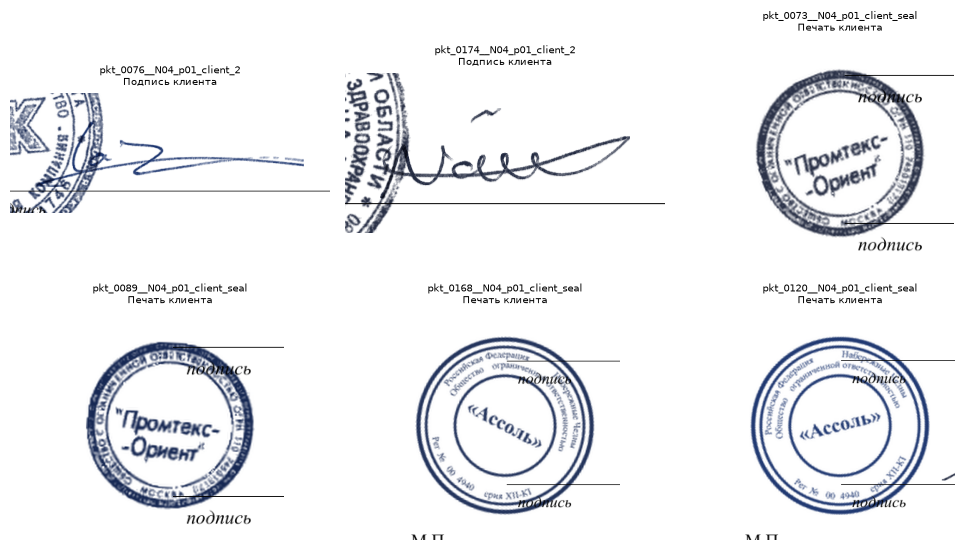

In [9]:
overlap_summary = []
for kind in ("signature", "stamp"):
    g = [m for m in pmeasure if m["kind"] == kind]
    overlap_summary.append(
        {
            "Объект": kind,
            "Есть пересечение с другими чернилами, %": round(
                100 * np.mean([m["overlap_other"] > 0 for m in g]), 2
            ),
            "Пересечение >10% чернил, %": round(
                100 * np.mean([m["overlap_other"] > 0.1 for m in g]), 2
            ),
            "Есть пересечение с линиями, %": round(
                100 * np.mean([m["overlap_lines"] > 0 for m in g]), 2
            ),
            "Есть пересечение с тёмным текстовым фоном, %": round(
                100 * np.mean([m["overlap_text_proxy"] > 0 for m in g]), 2
            ),
        }
    )
ptable(overlap_summary, "07_overlap")
overlapping = [p for p in overlap_pairs if p["intersection_ink_pixels"] > 0]
same = sum(p["same_color"] for p in overlapping)
print(f"Пар с пересечением чернил: {len(overlapping)}; из них одинаковый цвет: {same}.")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for kind, label in [("signature", "Подписи"), ("stamp", "Печати")]:
    g = [m for m in pmeasure if m["kind"] == kind]
    for ax, key in zip(axes, ["overlap_other", "overlap_lines", "overlap_text_proxy"]):
        ax.hist([m[key] * 100 for m in g], bins=30, alpha=0.45, label=label)
for ax, title in zip(
    axes, ["Другие рукописные чернила", "Линии бланка", "Тёмный фон без длинных линий"]
):
    ax.set(
        title=title, xlabel="Доля целевых чернил в пересечении, %", ylabel="Объектов"
    )
    ax.legend(fontsize=8)
pfig(fig, "07_overlap_distributions")
overlap_examples = []
for key in ("overlap_other", "overlap_lines", "overlap_text_proxy"):
    for m in sorted(pmeasure, key=lambda m: -m[key])[:2]:
        if m["id"] not in [o["id"] for o in overlap_examples]:
            overlap_examples.append(pobject_by[m["id"]])
object_grid(overlap_examples, "07_overlap_examples", cols=3)
pres["overlap"] = {
    "summary": overlap_summary,
    "overlapping_signature_stamp_pairs": len(overlapping),
    "same_color_overlapping_pairs": same,
}
pnotes["7"] = (
    f"Найдено {len(overlapping)} пар подпись–печать с "
    f"пересечением сильных пикселей, у {same} пар одинаковый "
    f"цвет. Пересечения с печатным фоном и линиями посчитаны "
    f"отдельно, но текстовый фон выделен эвристически, без OCR. "
    f"Доля пересечения не является долей потерянной информации "
    f"или оценкой качества модели."
)

**Результат и вывод.** Пересекаются чернила 45 пар подпись–печать, у 18 пар одинаковый цвет; максимальная доля пересечения целевых чернил с другими — 14.1%. Пересечений подписей с выделенными длинными линиями не найдено: сложные наложения представлены слабо. Тёмный текстовый фон выделен эвристически; эти доли не измеряют потерю информации.

## Страницы 8. Комплекты и эталоны

Проверяем полные/частичные комплекты, наличие активных эталонов и различие естественных сканов reference/query. Не используем карантин как скрытый источник эталонов. Отдельно фиксируем ограничение шаблонных печатей.

Комплект,Страниц,Активных эталонов,Для сравнения есть эталоны
pkt_0086,12,0,False
pkt_0152,12,3,True
pkt_0158,12,3,True


Проверка,Количество
query_objects,2875
identity_mismatch,0
same_natural_signature_scan,0
same_stamp_template_positive,954
query_without_active_reference,14


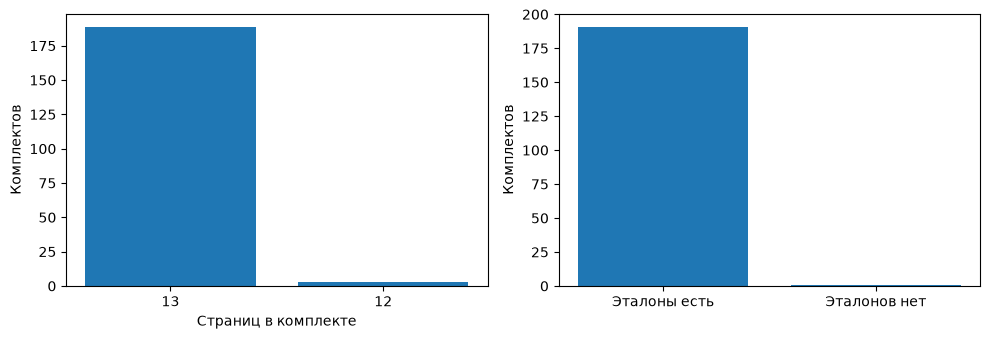

In [10]:
by_packet = defaultdict(list)
for r in prows:
    by_packet[r["packet_id"]].append(r)
packet_checks = []
query_checks = Counter()
for packet, group in sorted(by_packet.items()):
    obs = [o for r in group for o in r["objects"]]
    refs = {o["actor"]: o for o in obs if o["comparison_use"] == "reference"}
    missing = not refs
    packet_checks.append(
        {
            "Комплект": packet,
            "Страниц": len(group),
            "Активных эталонов": len(refs),
            "Для сравнения есть эталоны": not missing,
        }
    )
    for o in obs:
        if o["comparison_use"] != "query":
            continue
        query_checks["query_objects"] += 1
        if o["actor"] not in refs:
            query_checks["query_without_active_reference"] += 1
            continue
        query_checks["identity_mismatch"] += int(
            o["identity"] != refs[o["actor"]]["identity"]
        )
        if o["kind"] == "signature":
            query_checks["same_natural_signature_scan"] += int(
                o["source_id"] == refs[o["actor"]]["source_id"]
            )
        else:
            query_checks["same_stamp_template_positive"] += int(
                o["source_id"] == refs[o["actor"]]["source_id"]
            )
partial = [p for p in packet_checks if p["Страниц"] != 13]
ptable(partial, "08_partial_packets")
ptable(
    [{"Проверка": k, "Количество": v} for k, v in query_checks.items()],
    "08_reference_query",
)
assert (
    query_checks["identity_mismatch"] == 0
    and query_checks["same_natural_signature_scan"] == 0
)
assert [
    p["Комплект"] for p in packet_checks if not p["Для сравнения есть эталоны"]
] == ["pkt_0086"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
counts = Counter(p["Страниц"] for p in packet_checks)
axes[0].bar([str(k) for k in counts], list(counts.values()))
axes[0].set(xlabel="Страниц в комплекте", ylabel="Комплектов")
axes[1].bar(
    ["Эталоны есть", "Эталонов нет"],
    [
        sum(p["Для сравнения есть эталоны"] for p in packet_checks),
        sum(not p["Для сравнения есть эталоны"] for p in packet_checks),
    ],
)
axes[1].set_ylabel("Комплектов")
pfig(fig, "08_packet_completeness")
pres["packets"] = {
    "partial": partial,
    "reference_checks": dict(query_checks),
    "complete": sum(p["Страниц"] == 13 for p in packet_checks),
    "with_references": sum(p["Для сравнения есть эталоны"] for p in packet_checks),
}
pnotes["8"] = (
    f"Полных комплектов {pres['packets']['complete']}, частичных "
    f"{len(partial)}; активные эталоны есть у "
    f"{pres['packets']['with_references']} комплектов. В pkt_0086 "
    f"нет эталонной страницы: "
    f"{query_checks['query_without_active_reference']} "
    f"query-объектов не участвуют в полноценном сравнении. У "
    f"доступных пар подписи identities совпадают и естественные "
    f"сканы различаются; положительные пары печатей остаются "
    f"вариантами одного шаблона, без независимых реальных "
    f"оттисков."
)

**Результат и вывод.** Полных комплектов 189, частичных 3; активные эталоны есть у 191 комплекта. В pkt_0086 нет эталонной страницы, 14 query-объектов исключены из полноценного сравнения. У доступных пар identities согласованы, естественные сканы подписей различаются; печати остаются вариантами тех же шаблонов, без независимых оттисков.

## Страницы 9. Подсказки генератора и риски утечек

Смотрим связи identity с цветом, размером, поворотом, ролью и типом документа. NMI сравниваем с 50 перемешиваниями как диагностическим фоном, не статистическим тестом. Проверяем общие источники между комплектами и исходными группами, split не назначаем.

Объект,Признак,NMI,Медиана при перемешивании,95% диагностического фона
signature,Цвет,0.0266,0.0268,0.0292
signature,Поворот (8 интервалов),0.0159,0.0164,0.0181
signature,Размер (квантили),0.0357,0.0371,0.04
signature,Роль,0.1542,0.0398,0.0424
signature,Тип документа,0.0563,0.048,0.051
signature,Вертикальное положение (5 зон),0.0261,0.0402,0.0435
stamp,Цвет,0.0089,0.0061,0.009
stamp,Поворот (8 интервалов),0.0121,0.0144,0.0184
stamp,Размер (квантили),0.6396,0.0092,0.0124
stamp,Роль,0.0,0.004,0.0059


Исходная группа A,Исходная группа B,Общих людей,Общих групп печатей
test,train,0,16
test,val,0,16
train,val,0,16


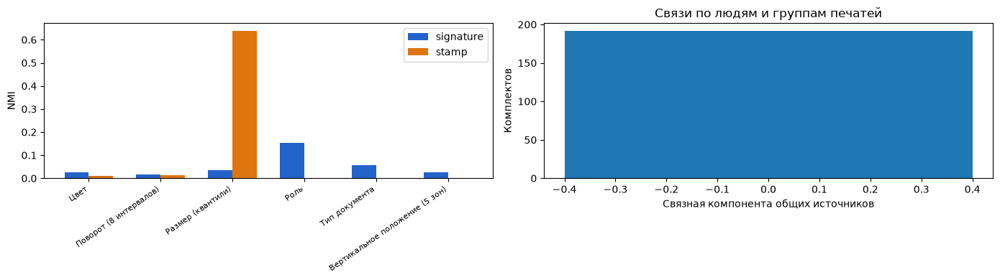

In [11]:
def nmi(x, y):
    _, xx = np.unique(np.array(x, dtype=str), return_inverse=True)
    _, yy = np.unique(np.array(y, dtype=str), return_inverse=True)
    joint = (
        np.bincount(xx * (yy.max() + 1) + yy, minlength=(xx.max() + 1) * (yy.max() + 1))
        .reshape(xx.max() + 1, yy.max() + 1)
        .astype(float)
    )
    joint /= joint.sum()
    px = joint.sum(1)
    py = joint.sum(0)
    expected = px[:, None] * py[None, :]
    nz = joint > 0
    mi = float((joint[nz] * np.log(joint[nz] / expected[nz])).sum())
    hx = float(-(px[px > 0] * np.log(px[px > 0])).sum())
    hy = float(-(py[py > 0] * np.log(py[py > 0])).sum())
    return mi / math.sqrt(hx * hy) if hx * hy else 0.0


associations = []
for kind in ("signature", "stamp"):
    g = [m for m in pmeasure if m["kind"] == kind]
    ids = [m["identity"] if kind == "signature" else m["seal_guard_group"] for m in g]
    features = {
        "Цвет": [m["color"] for m in g],
        "Поворот (8 интервалов)": [int((m["rotation"] + 30) // 7.5) for m in g],
        "Размер (квантили)": [float(m["min_side_px"]) for m in g],
        "Роль": [m["actor"] for m in g],
        "Тип документа": [m["family"] for m in g],
        "Вертикальное положение (5 зон)": [min(4, int(m["cy"] * 5)) for m in g],
    }
    values = np.array(features["Размер (квантили)"])
    edges = np.unique(np.quantile(values, [0.2, 0.4, 0.6, 0.8]))
    features["Размер (квантили)"] = np.digitize(values, edges).tolist()
    for feature, values in features.items():
        actual = nmi(ids, values)
        background = [nmi(ids, prng.permutation(values)) for _ in range(50)]
        associations.append(
            {
                "Объект": kind,
                "Признак": feature,
                "NMI": round(actual, 4),
                "Медиана при перемешивании": round(float(np.median(background)), 4),
                "95% диагностического фона": round(
                    float(np.percentile(background, 95)), 4
                ),
            }
        )
ptable(associations, "09_identity_associations")
origin = defaultdict(lambda: {"people": set(), "scans": set(), "seals": set()})
for r in prows:
    part = r["origin_signature_partition"]
    for o in r["objects"]:
        origin[part]["people" if o["kind"] == "signature" else "seals"].add(
            o["identity"] if o["kind"] == "signature" else o["seal_guard_group"]
        )
leaks = []
for a, b in combinations(sorted(origin), 2):
    leaks.append(
        {
            "Исходная группа A": a,
            "Исходная группа B": b,
            "Общих людей": len(origin[a]["people"] & origin[b]["people"]),
            "Общих групп печатей": len(origin[a]["seals"] & origin[b]["seals"]),
        }
    )
ptable(leaks, "09_origin_partition_intersections")
parent = {p: p for p in by_packet}


def root(p):
    while parent[p] != p:
        parent[p] = parent[parent[p]]
        p = parent[p]
    return p


first = {}
for r in prows:
    for o in r["objects"]:
        key = (
            o["kind"],
            o["identity"] if o["kind"] == "signature" else o["seal_guard_group"],
        )
        if key in first:
            parent[root(r["packet_id"])] = root(first[key])
        else:
            first[key] = r["packet_id"]
components = Counter(root(p) for p in by_packet)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for kind, offset, color in [
    ("signature", -0.17, "#2463c9"),
    ("stamp", 0.17, "#df750e"),
]:
    g = [r for r in associations if r["Объект"] == kind]
    xx = np.arange(len(g)) + offset
    axes[0].bar(xx, [r["NMI"] for r in g], width=0.34, label=kind, color=color)
axes[0].set_xticks(np.arange(6))
axes[0].set_xticklabels(
    [r["Признак"] for r in associations[:6]], rotation=35, ha="right", fontsize=8
)
axes[0].set_ylabel("NMI")
axes[0].legend()
axes[1].bar(range(len(components)), sorted(components.values(), reverse=True))
axes[1].set(
    xlabel="Связная компонента общих источников",
    ylabel="Комплектов",
    title="Связи по людям и группам печатей",
)
pfig(fig, "09_leakage_risks")
pres["leakage"] = {
    "associations": associations,
    "origin_intersections": leaks,
    "joint_source_component_sizes": sorted(components.values(), reverse=True),
    "split_assigned": any(r["dataset_split"] is not None for r in prows),
    "permutation_caveat": (
        "objects are dependent; permutation baseline is descriptive, "
        "not a valid iid significance test"
    ),
}
pnotes["9"] = (
    f"Совместный split не назначен. По людям и группам печатей "
    f"комплекты образуют {len(components)} связных компонент, "
    f"крупнейшая содержит {max(components.values())} комплектов. "
    f"Исходная группировка подписей не изолирует печати. Связи с "
    f"размером/положением могут объясняться источником и макетом; "
    f"случайное разделение страниц не даст независимой проверки."
)

**Результат и вывод.** Все 192 комплекта связаны общими людьми и группами печатей; исходные группы подписей разделяют людей, но содержат одни и те же 16 групп печатей. Размер печати заметно связан с её источником (NMI≈0.64), цвет и поворот близки к диагностическому фону. Случайный split страниц не обеспечит независимость; исключать шаблоны из-за этой связи не требуется.

## Страницы 10. Визуальный обзор и итог

Показываем все пять типов документов, все 17 шаблонов печатей и воспроизводимую случайную выборку. Сводим ограничения, не меняя данные и не утверждая соответствие закрытому банковскому потоку.

Сформированы визуальные примеры и список ограничений. Данные не менялись.


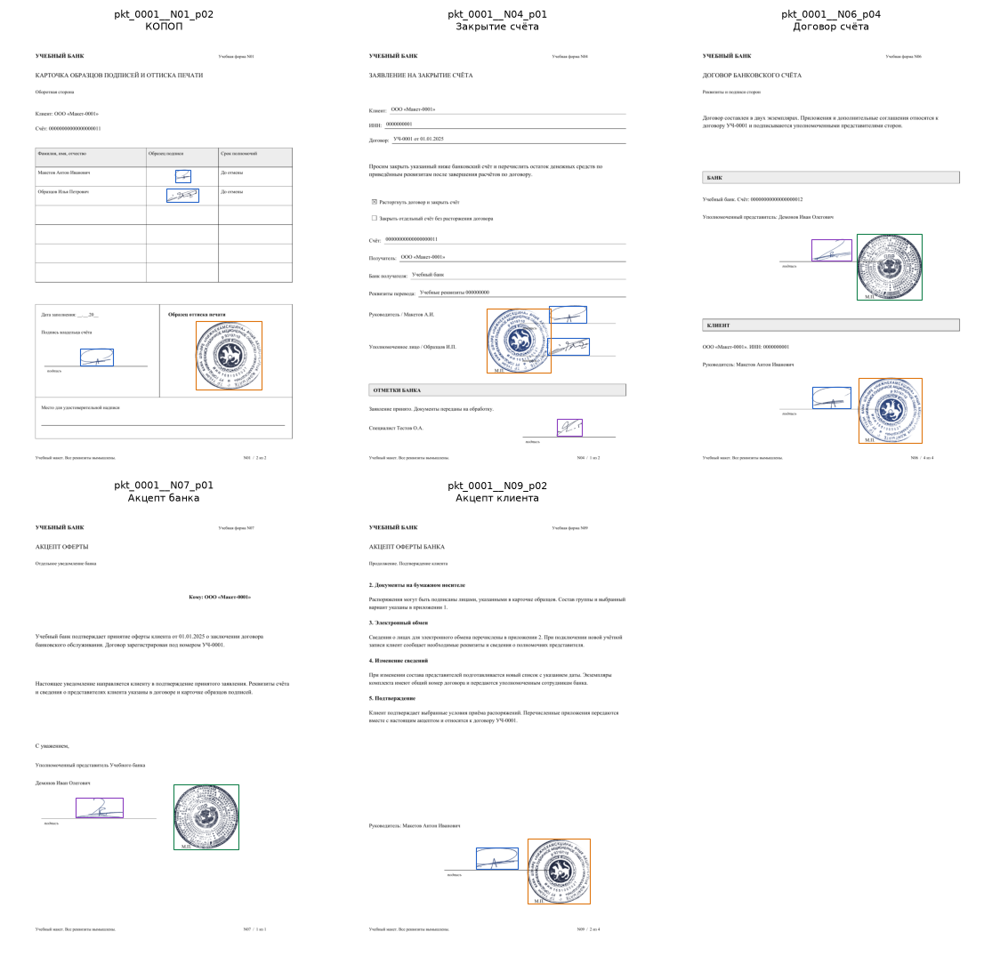

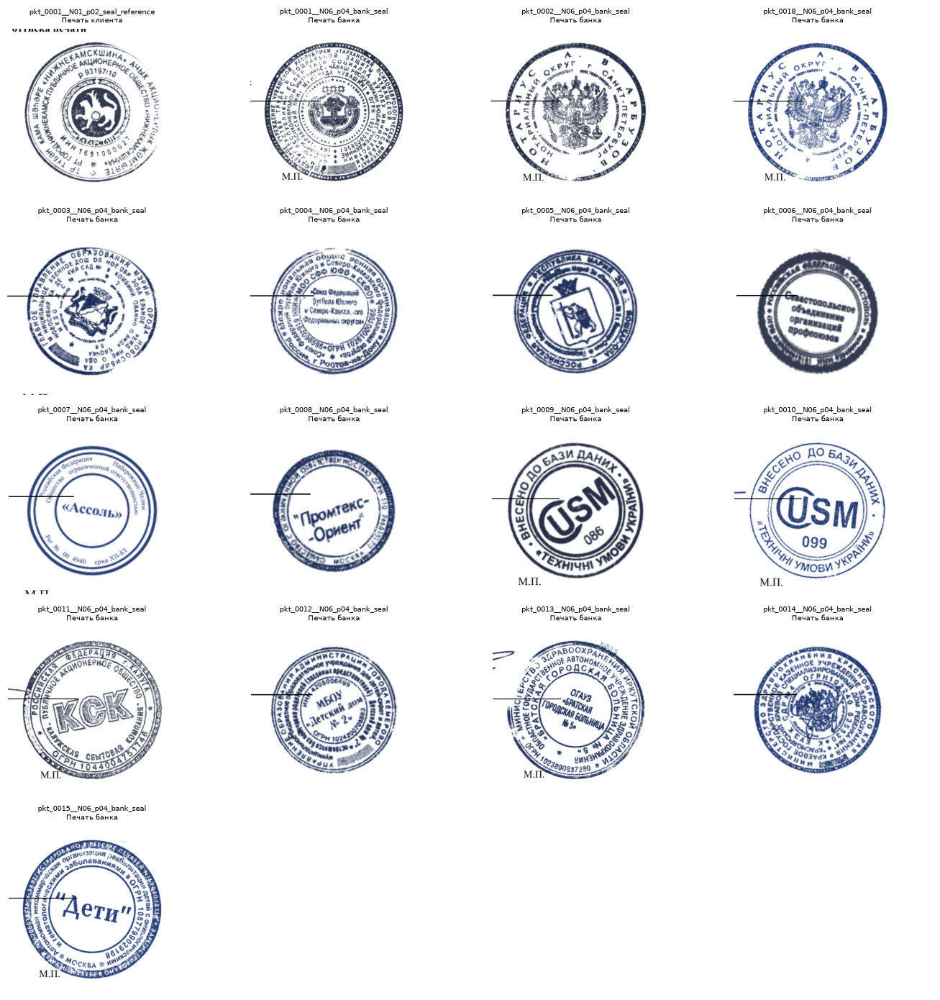

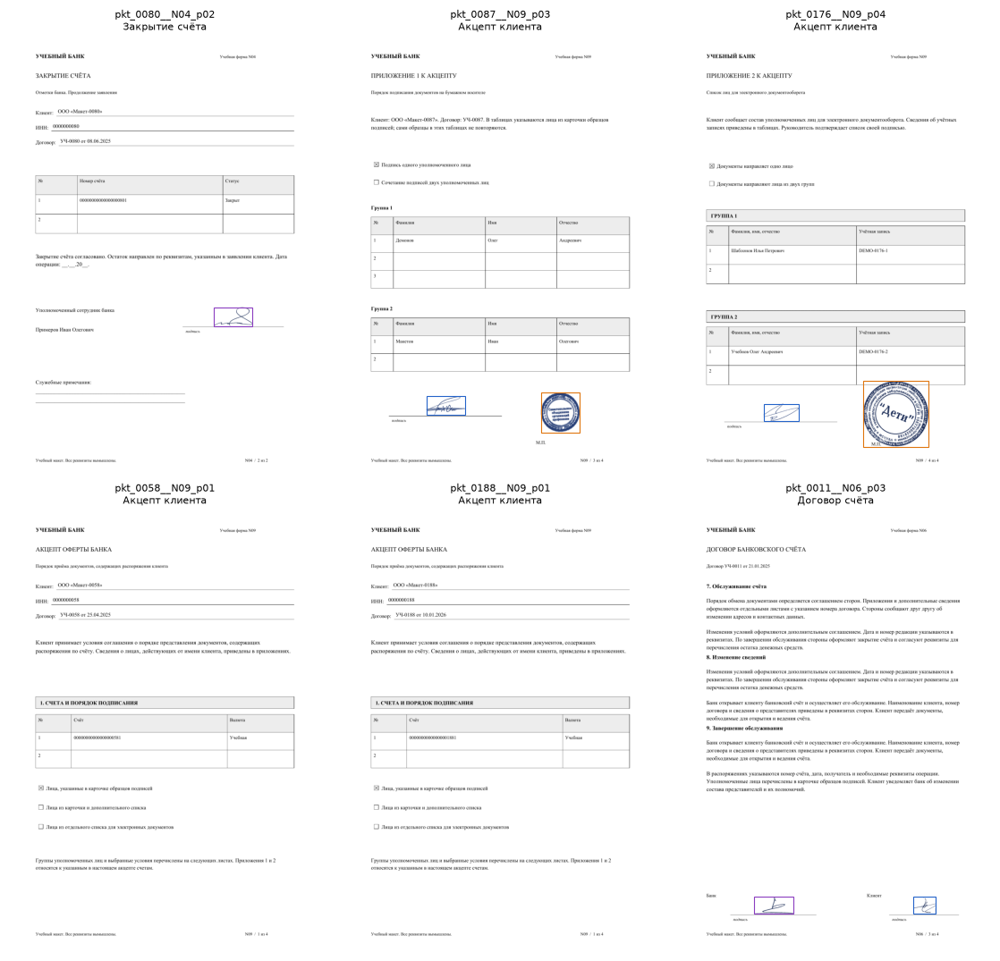

In [12]:
representative = []
for family in FAMILY_LABELS:
    candidates = [r for r in prows if r["family"] == family]
    representative.append(max(candidates, key=lambda r: len(r["objects"])))
page_grid(representative, "10_document_families", cols=3)
seal_examples = []
for source in sorted(seal_uses):
    seal_examples.append(
        next(o for o in pobjects if o["kind"] == "stamp" and o["source_id"] == source)
    )
object_grid(seal_examples, "10_all_17_stamp_templates", cols=4)
random_pages = [prows[int(i)] for i in prng.choice(len(prows), 6, replace=False)]
page_grid(random_pages, "10_seeded_random_pages", cols=3)
review_ids = {
    "family_pages": [r["page_id"] for r in representative],
    "seal_objects": [o["id"] for o in seal_examples],
    "random_pages": [r["page_id"] for r in random_pages],
}
psave("visual_review_sample.json", review_ids)
pres["visual"] = review_ids
pnotes["10"] = (
    "Показаны пять типов документов, все 17 шаблонов печатей и "
    "шесть случайных страниц; крайние случаи есть в предыдущих "
    "блоках. Это выборочный визуальный контроль синтетики. "
    "Повторяемость макетов и ограниченность источников остаются; "
    "независимых реальных страниц банка для оценки переноса нет."
)
print("Сформированы визуальные примеры и список ограничений. Данные не менялись.")

**Результат и вывод.** Показаны пять типов документов, все 17 шаблонов печатей и шесть случайных страниц; крайние случаи есть в предыдущих блоках. Это выборочный визуальный контроль синтетики. Повторяемость макетов и ограниченность источников остаются; независимых реальных страниц банка для оценки переноса нет.

## Страницы — итог и контроль сохранности

Сохраняем измерения и выводы, перепроверяем все прочитанные входные файлы по хешам. Ни один найденный признак не используется для автоматического исключения данных.
Валидация, схема классов, бейзлайн и размер входа остаются решениями следующего этапа, а не результатами этого EDA.

In [13]:
changed = [p for p, h in pfingerprints.items() if phashfile(ROOT / p) != h]
assert not changed, changed
psave("input_fingerprints.json", pfingerprints)
pres["input_integrity"] = {
    "files_rechecked": len(pfingerprints),
    "changed_files": changed,
}
pres["conclusions"] = pnotes
psave("eda_results.json", pres)
print(
    f"Входных файлов повторно проверено: {len(pfingerprints)}; "
    f"изменённых: {len(changed)}."
)
print(
    "Главные ограничения: повторяемость макетов и источников; "
    "один комплект без эталонов; зависимость объектов от "
    "масштаба страницы; совместный split не согласован."
)

Входных файлов повторно проверено: 14774; изменённых: 0.
Главные ограничения: повторяемость макетов и источников; один комплект без эталонов; зависимость объектов от масштаба страницы; совместный split не согласован.


## Страницы — основные выводы

- Техническая целостность подтверждена: 2493 страницы, 5366 объектов, 17 шаблонов печатей; точных дублей нет.
- Источники и макеты повторяются. Все 192 комплекта связаны; совместную валидацию нужно согласовать отдельно, случайное деление страниц недостаточно.
- При уменьшении до 640 px штрихи ухудшаются; размер входа и способ обработки страницы ещё не выбраны.
- Сильные наложения редки, а подписи не пересекают выделенные длинные линии бланков: это ограничение сложности синтетики.
- Обнаружен остаток фона в одном слое подписи (две вставки). Находка зафиксирована, автоматического удаления или очистки не было.

Датасеты и прежний раздел EDA кропов сохранены без изменений. Нормализацию размера печатей и протокол валидации следует обсудить, сохраняя разнообразие шаблонов; обучение не выполнялось.